# W7-M1.1 — Recover the DifficultyOnly Streak Rule

Before comparing my history-based predictor against Sam's DifficultyOnly scheduler, I first recover the exact streak heuristic used in the live run.

The rollout logs contain prompt outcomes, but they do not record the scheduler's internal skip probability or streak state. I therefore inspect the DUET scheduler implementation directly rather than approximating the rule from the data.

I want to identify:
- how a dead streak is defined and updated
- how streak length is converted into skip probability
- the exploration floor or minimum keep probability
- how cold-start prompts are handled
- whether skipping is probabilistic or deterministic
- when scheduler state is updated relative to the current batch

This recovered rule becomes the frozen baseline for the Week 7 predictor comparison.

In [2]:
from pathlib import Path

# ============================================================
# W7-M1.2A — Locate My Downloaded Prompt-Streak Logs
# ============================================================

ROOT = Path(
    r"C:\Users\waqar\OneDrive\Desktop\Fellowship"
)

allowed_suffixes = {
    ".csv",
    ".jsonl",
    ".json",
    ".parquet",
    ".txt",
}

matches = []

for path in ROOT.rglob("*"):
    if not path.is_file():
        continue

    path_lower = str(path).lower()

    if (
        ("streak" in path_lower or "prompt_streak" in path_lower)
        and path.suffix.lower() in allowed_suffixes
    ):
        matches.append(path)

print("=" * 100)
print("PROMPT-STREAK FILE SEARCH")
print("=" * 100)

print(f"\nFiles found: {len(matches)}\n")

for i, path in enumerate(matches, start=1):
    size_kb = path.stat().st_size / 1024

    print(
        f"{i:>3}. "
        f"{path.relative_to(ROOT)}"
        f"   |   {size_kb:.2f} KB"
    )

PROMPT-STREAK FILE SEARCH

Files found: 32

  1. prompt_streak\1.json   |   3.23 KB
  2. prompt_streak\10.json   |   14.61 KB
  3. prompt_streak\11.json   |   15.98 KB
  4. prompt_streak\12.json   |   17.36 KB
  5. prompt_streak\13.json   |   18.73 KB
  6. prompt_streak\14.json   |   20.11 KB
  7. prompt_streak\15.json   |   21.48 KB
  8. prompt_streak\16.json   |   22.86 KB
  9. prompt_streak\2.json   |   4.48 KB
 10. prompt_streak\3.json   |   5.73 KB
 11. prompt_streak\4.json   |   6.98 KB
 12. prompt_streak\5.json   |   8.23 KB
 13. prompt_streak\6.json   |   9.48 KB
 14. prompt_streak\7.json   |   10.73 KB
 15. prompt_streak\8.json   |   11.98 KB
 16. prompt_streak\9.json   |   13.23 KB
 17. prompt_streak\rollout_data\1.jsonl   |   2337.93 KB
 18. prompt_streak\rollout_data\10.jsonl   |   1946.23 KB
 19. prompt_streak\rollout_data\11.jsonl   |   1900.39 KB
 20. prompt_streak\rollout_data\12.jsonl   |   1811.26 KB
 21. prompt_streak\rollout_data\13.jsonl   |   2048.96 KB
 22. promp

# W7-M1.2B — Load and Verify the Matched Streak Run

I located the complete Week 7 streak dataset: 16 prompt-streak snapshots and 16 matching rollout files.

I now load the two sources directly and verify their structure before constructing any predictor features.

At this stage I only check:
- that both sources contain steps 1 through 16
- that every streak snapshot contains 128 prompt IDs
- that every rollout step contains 640 generated responses
- that the rollout schema is consistent across steps
- that the saved streak histories grow chronologically with the run

I do not yet interpret the saved streak value. That will be verified directly against the rollout rewards in the next step.

In [3]:
from pathlib import Path
import json
import pandas as pd

# ============================================================
# W7-M1.2B — Load and Verify the Matched Streak Run
# ============================================================

STREAK_DIR = Path(
    r"C:\Users\waqar\OneDrive\Desktop\Fellowship\prompt_streak"
)

ROLLOUT_DIR = STREAK_DIR / "rollout_data"

# ------------------------------------------------------------
# 1. Collect files in numerical / chronological order
# ------------------------------------------------------------

streak_files = sorted(
    [p for p in STREAK_DIR.glob("*.json")],
    key=lambda p: int(p.stem)
)

rollout_files = sorted(
    [p for p in ROLLOUT_DIR.glob("*.jsonl")],
    key=lambda p: int(p.stem)
)

print("=" * 90)
print("FILE COUNTS")
print("=" * 90)

print("Streak files :", len(streak_files))
print("Rollout files:", len(rollout_files))

print("\nStreak steps :", [int(p.stem) for p in streak_files])
print("Rollout steps:", [int(p.stem) for p in rollout_files])


# ------------------------------------------------------------
# 2. Audit streak snapshots
# ------------------------------------------------------------

streak_audit = []

for path in streak_files:
    step = int(path.stem)

    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    history_lengths = [len(v) for v in data.values()]

    streak_audit.append({
        "step": step,
        "n_prompts": len(data),
        "min_history_len": min(history_lengths),
        "max_history_len": max(history_lengths),
    })

streak_audit = pd.DataFrame(streak_audit)

print("\n" + "=" * 90)
print("STREAK SNAPSHOT AUDIT")
print("=" * 90)

display(streak_audit)


# ------------------------------------------------------------
# 3. Audit rollout files
# ------------------------------------------------------------

rollout_audit = []

for path in rollout_files:
    file_step = int(path.stem)
    df = pd.read_json(path, lines=True)

    rollout_audit.append({
        "file_step": file_step,
        "rows": len(df),
        "unique_uid": df["uid"].nunique(),
        "n_step_values": df["step"].nunique(),
        "step_values": tuple(sorted(df["step"].unique())),
        "columns": tuple(sorted(df.columns)),
    })

rollout_audit = pd.DataFrame(rollout_audit)

print("\n" + "=" * 90)
print("ROLLOUT AUDIT")
print("=" * 90)

display(rollout_audit)


# ------------------------------------------------------------
# 4. Inspect one actual streak snapshot
# ------------------------------------------------------------

with open(streak_files[0], "r", encoding="utf-8") as f:
    step1_streak = json.load(f)

with open(streak_files[-1], "r", encoding="utf-8") as f:
    step16_streak = json.load(f)

sample_prompt = next(iter(step1_streak))

print("\n" + "=" * 90)
print("EXAMPLE SAVED HISTORY")
print("=" * 90)

print("Prompt ID:", sample_prompt)

print("\nStep 1 snapshot:")
print(step1_streak[sample_prompt])

print("\nStep 16 snapshot:")
print(step16_streak[sample_prompt])


# ------------------------------------------------------------
# 5. Structural assertions
# ------------------------------------------------------------

assert len(streak_files) == 16
assert len(rollout_files) == 16

assert streak_audit["n_prompts"].eq(128).all()
assert streak_audit["min_history_len"].tolist() == list(range(1, 17))
assert streak_audit["max_history_len"].tolist() == list(range(1, 17))

assert rollout_audit["rows"].eq(640).all()

print("\n Matched 16-step streak/rollout structure verified.")

FILE COUNTS
Streak files : 16
Rollout files: 16

Streak steps : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
Rollout steps: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]

STREAK SNAPSHOT AUDIT


,step,n_prompts,min_history_len,max_history_len
0,1,128,1,1
1,2,128,2,2
2,3,128,3,3
3,4,128,4,4
4,5,128,5,5
5,6,128,6,6
6,7,128,7,7
7,8,128,8,8
8,9,128,9,9
9,10,128,10,10



ROLLOUT AUDIT


,file_step,rows,unique_uid,n_step_values,step_values,columns
0,1,640,640,1,"(1,)","(gts, input, output, score, step, uid)"
1,2,640,640,1,"(2,)","(gts, input, output, score, step, uid)"
2,3,640,640,1,"(3,)","(gts, input, output, score, step, uid)"
3,4,640,640,1,"(4,)","(gts, input, output, score, step, uid)"
4,5,640,640,1,"(5,)","(gts, input, output, score, step, uid)"
5,6,640,640,1,"(6,)","(gts, input, output, score, step, uid)"
6,7,640,640,1,"(7,)","(gts, input, output, score, step, uid)"
7,8,640,640,1,"(8,)","(gts, input, output, score, step, uid)"
8,9,640,640,1,"(9,)","(gts, input, output, score, step, uid)"
9,10,640,640,1,"(10,)","(gts, input, output, score, step, uid)"



EXAMPLE SAVED HISTORY
Prompt ID: train_6406

Step 1 snapshot:
[[1, 0.2]]

Step 16 snapshot:
[[1, 0.2], [2, 0.0], [3, 0.2], [4, 0.0], [5, 0.0], [6, 0.0], [7, 0.0], [8, 0.0], [9, 0.0], [10, 0.0], [11, 0.2], [12, 0.4], [13, 0.0], [14, 0.4], [15, 0.4], [16, 0.2]]

 Matched 16-step streak/rollout structure verified.


# W7-M1.2C — Verify the Meaning of the Saved Streak Value

The saved history for each prompt contains pairs such as `[step, 0.2]`, `[step, 0.0]`, and `[step, 0.4]`.

Before using these values as difficulty history, I verify their meaning directly against the raw rollout rewards.

For each prompt at each step, I:
- identify its five rollout rows
- compute the mean rollout score
- compare that mean against the value stored in the prompt-streak history for the same step

If the values match exactly, I can interpret the saved history value as the prompt-level pass rate for that step.

This verification matters because all later definitions of dead prompts, dead streaks, and history features depend on the semantics of this saved value.

In [4]:
import re
import json
import numpy as np
import pandas as pd

# ============================================================
# W7-M1.2C1 — Recover Prompt Groups and Test Ordering
# ============================================================

# ------------------------------------------------------------
# Load Step 1 only
# ------------------------------------------------------------

rollout_path = rollout_files[0]
streak_path = streak_files[0]

df = pd.read_json(rollout_path, lines=True)

with open(streak_path, "r", encoding="utf-8") as f:
    streak_data = json.load(f)


# ------------------------------------------------------------
# Recover prompt occurrence UUID by removing rollout suffix
#
# Example:
# abc-def-..._0_0
# abc-def-..._1_0
# ...
# becomes:
# abc-def-...
# ------------------------------------------------------------

df["occurrence_id"] = (
    df["uid"]
    .astype(str)
    .str.replace(r"_\d+_\d+$", "", regex=True)
)

print("=" * 90)
print("ROLLOUT UID STRUCTURE")
print("=" * 90)

print("\nFirst 10 raw UIDs:")
print(df["uid"].head(10).to_string(index=False))

print("\nFirst 10 recovered occurrence IDs:")
print(df["occurrence_id"].head(10).to_string(index=False))

print("\nUnique prompt occurrences:", df["occurrence_id"].nunique())


# ------------------------------------------------------------
# Preserve native first-seen prompt ordering in the JSONL
# ------------------------------------------------------------

first_seen_order = (
    df[["occurrence_id"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

first_seen_order["rollout_order"] = np.arange(len(first_seen_order))


# ------------------------------------------------------------
# Compute five-rollout pass rate for each occurrence
# ------------------------------------------------------------

prompt_scores = (
    df.groupby("occurrence_id", as_index=False, sort=False)
    .agg(
        rollout_pass_rate=("score", "mean"),
        n_rollouts=("score", "size"),
    )
)

prompt_scores = first_seen_order.merge(
    prompt_scores,
    on="occurrence_id",
    how="left",
    validate="one_to_one",
)


# ------------------------------------------------------------
# Extract Step-1 streak entries in saved dictionary order
# ------------------------------------------------------------

streak_rows = []

for streak_order, (prompt_id, history) in enumerate(streak_data.items()):

    assert len(history) == 1

    saved_step, saved_value = history[0]

    streak_rows.append({
        "streak_order": streak_order,
        "streak_prompt_id": prompt_id,
        "saved_step": int(saved_step),
        "saved_pass_rate": float(saved_value),
    })

streak_step1 = pd.DataFrame(streak_rows)


# ------------------------------------------------------------
# Compare by position only
# ------------------------------------------------------------

order_check = pd.concat(
    [
        prompt_scores.reset_index(drop=True),
        streak_step1.reset_index(drop=True),
    ],
    axis=1,
)

order_check["abs_diff"] = (
    order_check["rollout_pass_rate"]
    - order_check["saved_pass_rate"]
).abs()


print("\n" + "=" * 90)
print("ORDERING DIAGNOSTIC")
print("=" * 90)

print("Rollout prompt groups:", len(prompt_scores))
print("Streak prompt entries:", len(streak_step1))

print(
    "All rollout groups have 5 rollouts:",
    prompt_scores["n_rollouts"].eq(5).all()
)

print(
    "Max positional pass-rate difference:",
    order_check["abs_diff"].max()
)

print(
    "Exact positional pass-rate matches:",
    np.isclose(
        order_check["rollout_pass_rate"],
        order_check["saved_pass_rate"]
    ).sum(),
    "/",
    len(order_check)
)

print("\nFirst 15 positional comparisons:")

display(
    order_check[
        [
            "rollout_order",
            "occurrence_id",
            "rollout_pass_rate",
            "streak_prompt_id",
            "saved_pass_rate",
            "abs_diff",
        ]
    ].head(15)
)

ROLLOUT UID STRUCTURE

First 10 raw UIDs:
001fd92a-64e1-40a2-80d4-f098c1fd4713_0_0
001fd92a-64e1-40a2-80d4-f098c1fd4713_1_0
001fd92a-64e1-40a2-80d4-f098c1fd4713_2_0
001fd92a-64e1-40a2-80d4-f098c1fd4713_3_0
001fd92a-64e1-40a2-80d4-f098c1fd4713_4_0
0067f583-25b4-4d8e-bab1-76bdab294c67_0_0
0067f583-25b4-4d8e-bab1-76bdab294c67_1_0
0067f583-25b4-4d8e-bab1-76bdab294c67_2_0
0067f583-25b4-4d8e-bab1-76bdab294c67_3_0
0067f583-25b4-4d8e-bab1-76bdab294c67_4_0

First 10 recovered occurrence IDs:
001fd92a-64e1-40a2-80d4-f098c1fd4713
001fd92a-64e1-40a2-80d4-f098c1fd4713
001fd92a-64e1-40a2-80d4-f098c1fd4713
001fd92a-64e1-40a2-80d4-f098c1fd4713
001fd92a-64e1-40a2-80d4-f098c1fd4713
0067f583-25b4-4d8e-bab1-76bdab294c67
0067f583-25b4-4d8e-bab1-76bdab294c67
0067f583-25b4-4d8e-bab1-76bdab294c67
0067f583-25b4-4d8e-bab1-76bdab294c67
0067f583-25b4-4d8e-bab1-76bdab294c67

Unique prompt occurrences: 128

ORDERING DIAGNOSTIC
Rollout prompt groups: 128
Streak prompt entries: 128
All rollout groups have 5 rollouts:

,rollout_order,occurrence_id,rollout_pass_rate,streak_prompt_id,saved_pass_rate,abs_diff
0,0,001fd92a-64e1-40a2-80d4-f098c1fd4713,0.0,train_6406,0.2,0.2
1,1,0067f583-25b4-4d8e-bab1-76bdab294c67,0.0,train_2051,0.2,0.2
2,2,00a36fd0-2bb8-4645-93c6-d25686b179ed,0.0,train_3635,0.4,0.4
3,3,00fa5296-2b56-404b-8007-0b24524c2e52,0.0,train_379,0.2,0.2
4,4,03817956-fbda-4dfb-83d4-34e912af30c9,0.6,train_4572,0.2,0.4
5,5,03855a6c-4f6e-4b75-b591-aec220e593fe,0.0,train_3156,0.4,0.4
6,6,042f01ca-bfaf-4983-81c4-a295571064ab,0.4,train_7397,0.4,0.0
7,7,0643017d-42c3-4a09-9d44-a298f5a79335,0.0,train_7165,0.2,0.2
8,8,07a4d3f2-8d69-40a2-ab3d-d2c9241c7cac,0.4,train_514,0.2,0.2
9,9,08eaac40-ba14-4b45-97c9-7bba3a3765e4,0.2,train_7407,0.6,0.4


# W7-M1.2C2 — Reconcile Rollout Prompts with Saved Streak IDs

The rollout UUIDs and the saved `train_*` streak IDs use different identifier systems, and their file ordering does not correspond.

I therefore recover a stable rollout-side prompt identity from the exact prompt input and ground-truth answer, then track that same example across all 16 steps.

For each stable rollout prompt, I construct its 16-step pass-rate trajectory. I independently construct the corresponding 16-step trajectory for every saved `train_*` streak ID.

I then compare these trajectories as an identity-reconciliation check.

This full-trajectory comparison is used only to determine whether the two logging systems describe the same prompts. It is not used as a prediction feature. All later predictor features will still use only observations from earlier steps.

In [5]:
import hashlib
import json
import numpy as np
import pandas as pd

# ============================================================
# W7-M1.2C2 — Reconcile Rollout Prompts with Saved Streak IDs
# ============================================================

rollout_prompt_rows = []

# ------------------------------------------------------------
# 1. Build rollout-side prompt trajectories
# ------------------------------------------------------------

for path in rollout_files:

    step = int(path.stem)
    df = pd.read_json(path, lines=True)

    # Prompt occurrence UUID, removing rollout suffix
    df["occurrence_id"] = (
        df["uid"]
        .astype(str)
        .str.replace(r"_\d+_\d+$", "", regex=True)
    )

    # Aggregate 5 rollouts into one prompt occurrence
    grouped = (
        df.groupby("occurrence_id", as_index=False, sort=False)
        .agg(
            input=("input", "first"),
            gts=("gts", "first"),
            pass_rate=("score", "mean"),
            n_rollouts=("score", "size"),
        )
    )

    assert len(grouped) == 128
    assert grouped["n_rollouts"].eq(5).all()

    # Stable identity from exact prompt + ground truth
    def make_key(row):
        raw = (
            str(row["input"])
            + "\n<<<GTS>>>\n"
            + str(row["gts"])
        )
        return hashlib.sha256(raw.encode("utf-8")).hexdigest()

    grouped["stable_key"] = grouped.apply(make_key, axis=1)
    grouped["step"] = step

    rollout_prompt_rows.append(
        grouped[
            [
                "step",
                "stable_key",
                "input",
                "gts",
                "pass_rate",
            ]
        ]
    )

rollout_prompt_table = pd.concat(
    rollout_prompt_rows,
    ignore_index=True
)


# ------------------------------------------------------------
# 2. Check whether same stable prompts recur every step
# ------------------------------------------------------------

per_step_unique = (
    rollout_prompt_table
    .groupby("step")["stable_key"]
    .nunique()
)

all_step_sets = [
    set(
        rollout_prompt_table.loc[
            rollout_prompt_table["step"] == step,
            "stable_key"
        ]
    )
    for step in range(1, 17)
]

intersection_keys = set.intersection(*all_step_sets)
union_keys = set.union(*all_step_sets)

print("=" * 90)
print("STABLE PROMPT RECURRENCE")
print("=" * 90)

print("\nUnique stable prompts by step:")
print(per_step_unique.to_string())

print("\nIntersection across all 16 steps:", len(intersection_keys))
print("Union across all 16 steps       :", len(union_keys))


# ------------------------------------------------------------
# 3. Build rollout-side 16-step trajectory
# ------------------------------------------------------------

rollout_wide = (
    rollout_prompt_table
    .pivot(
        index="stable_key",
        columns="step",
        values="pass_rate"
    )
    .sort_index(axis=1)
)

print("\nRollout trajectory matrix shape:", rollout_wide.shape)
print(
    "Complete 16-step rollout trajectories:",
    rollout_wide.notna().all(axis=1).sum()
)


# ------------------------------------------------------------
# 4. Build streak-side 16-step trajectory
# ------------------------------------------------------------

with open(streak_files[-1], "r", encoding="utf-8") as f:
    final_streak = json.load(f)

streak_trajectory_rows = []

for prompt_id, history in final_streak.items():

    values = {
        int(step): float(value)
        for step, value in history
    }

    row = {"streak_prompt_id": prompt_id}

    for step in range(1, 17):
        row[step] = values.get(step, np.nan)

    streak_trajectory_rows.append(row)

streak_wide = (
    pd.DataFrame(streak_trajectory_rows)
    .set_index("streak_prompt_id")
    .sort_index(axis=1)
)

print("Streak trajectory matrix shape :", streak_wide.shape)
print(
    "Complete 16-step streak trajectories:",
    streak_wide.notna().all(axis=1).sum()
)


# ------------------------------------------------------------
# 5. Convert each 16-step trajectory into an exact signature
# ------------------------------------------------------------

def trajectory_signature(values):
    return tuple(
        round(float(x), 10)
        for x in values
    )

rollout_signatures = {
    stable_key: trajectory_signature(row.values)
    for stable_key, row in rollout_wide.iterrows()
}

streak_signatures = {
    prompt_id: trajectory_signature(row.values)
    for prompt_id, row in streak_wide.iterrows()
}

rollout_signature_counts = pd.Series(
    list(rollout_signatures.values())
).value_counts()

streak_signature_counts = pd.Series(
    list(streak_signatures.values())
).value_counts()


# ------------------------------------------------------------
# 6. Compare trajectory signature populations
# ------------------------------------------------------------

rollout_signature_multiset = sorted(
    rollout_signatures.values()
)

streak_signature_multiset = sorted(
    streak_signatures.values()
)

print("\n" + "=" * 90)
print("TRAJECTORY SIGNATURE CHECK")
print("=" * 90)

print(
    "Unique rollout trajectories:",
    len(set(rollout_signatures.values()))
)

print(
    "Unique streak trajectories :",
    len(set(streak_signatures.values()))
)

print(
    "Exact trajectory multiset match:",
    rollout_signature_multiset
    == streak_signature_multiset
)

print(
    "Rollout trajectories with collisions:",
    (rollout_signature_counts > 1).sum()
)

print(
    "Streak trajectories with collisions :",
    (streak_signature_counts > 1).sum()
)


# ------------------------------------------------------------
# 7. Show a few exact unique matches
# ------------------------------------------------------------

signature_to_streak_ids = {}

for prompt_id, sig in streak_signatures.items():
    signature_to_streak_ids.setdefault(sig, []).append(prompt_id)

example_matches = []

for stable_key, sig in rollout_signatures.items():

    candidates = signature_to_streak_ids.get(sig, [])

    if len(candidates) == 1:
        example_matches.append({
            "stable_key": stable_key[:12] + "...",
            "streak_prompt_id": candidates[0],
            "trajectory": sig,
        })

    if len(example_matches) == 8:
        break

print("\nExample exact trajectory matches:")
display(pd.DataFrame(example_matches))

STABLE PROMPT RECURRENCE

Unique stable prompts by step:
step
1     128
2     128
3     128
4     128
5     128
6     128
7     128
8     128
9     128
10    128
11    128
12    128
13    128
14    128
15    128
16    128

Intersection across all 16 steps: 128
Union across all 16 steps       : 128

Rollout trajectory matrix shape: (128, 16)
Complete 16-step rollout trajectories: 128
Streak trajectory matrix shape : (128, 16)
Complete 16-step streak trajectories: 128

TRAJECTORY SIGNATURE CHECK
Unique rollout trajectories: 125
Unique streak trajectories : 125
Exact trajectory multiset match: True
Rollout trajectories with collisions: 1
Streak trajectories with collisions : 1

Example exact trajectory matches:


,stable_key,streak_prompt_id,trajectory
0,02d354a2243b...,train_6871,"(0.0, 0.4, 0.0, 0.4, 0.2, 0.6, 0.6, 0.6, 0.4, ..."
1,04f6ddbb8b98...,train_5792,"(0.0, 0.2, 0.0, 0.2, 0.0, 0.2, 0.2, 0.0, 0.0, ..."
2,0874c17fa443...,train_3222,"(0.4, 0.2, 0.2, 0.8, 0.6, 0.4, 0.4, 0.6, 0.4, ..."
3,094ecae43b6f...,train_1505,"(0.2, 0.0, 0.4, 0.2, 0.0, 0.0, 0.6, 0.4, 0.0, ..."
4,0be907830087...,train_3662,"(0.4, 0.0, 0.2, 0.2, 0.2, 0.2, 0.0, 0.2, 0.2, ..."
5,13e76892c685...,train_6406,"(0.2, 0.0, 0.2, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
6,16825fb82121...,train_4828,"(0.0, 0.0, 0.0, 0.2, 0.0, 0.0, 0.2, 0.0, 0.0, ..."
7,1a44de23339d...,train_3279,"(0.0, 0.0, 0.0, 0.2, 0.0, 0.0, 0.0, 0.0, 0.2, ..."


# W7-M1.2C3 — Finalize Prompt Identity Reconciliation

The rollout data contains the same 128 stable prompts at every one of the 16 steps.

Most prompts can be matched directly to their saved `train_*` IDs using their complete 16-step pass-rate trajectories. I now verify that the full trajectory populations are identical and inspect the single duplicated trajectory before freezing the mapping.

The complete trajectory is used only to reconcile identifiers between logging systems. It will not be used as a prediction feature.

In [6]:
# ============================================================
# W7-M1.2C3 — Final Identity Check
# ============================================================

print("=" * 90)
print("FINAL IDENTITY SUMMARY")
print("=" * 90)

print("Rollout matrix shape:", rollout_wide.shape)
print("Streak matrix shape :", streak_wide.shape)

print(
    "\nExact trajectory multiset match:",
    rollout_signature_multiset == streak_signature_multiset
)

print(
    "Unique rollout trajectories:",
    len(set(rollout_signatures.values()))
)

print(
    "Unique streak trajectories :",
    len(set(streak_signatures.values()))
)


# ------------------------------------------------------------
# Find duplicated trajectory / collision
# ------------------------------------------------------------

duplicate_sigs = [
    sig
    for sig, count in rollout_signature_counts.items()
    if count > 1
]

print("\nNumber of duplicated trajectory signatures:", len(duplicate_sigs))

for i, sig in enumerate(duplicate_sigs, start=1):

    rollout_keys = [
        key
        for key, candidate_sig in rollout_signatures.items()
        if candidate_sig == sig
    ]

    streak_ids = [
        pid
        for pid, candidate_sig in streak_signatures.items()
        if candidate_sig == sig
    ]

    print("\n" + "-" * 90)
    print(f"Collision {i}")
    print("-" * 90)

    print("Trajectory:")
    print(sig)

    print("\nRollout stable keys:")
    for key in rollout_keys:
        print(" ", key)

    print("\nMatching streak IDs:")
    for pid in streak_ids:
        print(" ", pid)

FINAL IDENTITY SUMMARY
Rollout matrix shape: (128, 16)
Streak matrix shape : (128, 16)

Exact trajectory multiset match: True
Unique rollout trajectories: 125
Unique streak trajectories : 125

Number of duplicated trajectory signatures: 1

------------------------------------------------------------------------------------------
Collision 1
------------------------------------------------------------------------------------------
Trajectory:
(0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0)

Rollout stable keys:
  0807732bc593b230772e29e003eefeb85bb647e71c08531cf1749635463a44ae
  9e13b12d604323ce16619a1a604ef4fbf2428d73a002a5845a3d9e9a3033c0ab
  d55011b08457a2c391cbcc0bb15901095d3acbbb2a48923b8dd146a19b580b06
  eae95d6ed939cbb28cf5de8c500dc1abe91ca5a444eff02a94533e206cac0527

Matching streak IDs:
  train_4105
  train_3703
  train_5744
  train_4675


# W7-M1.3 — Build the Leakage-Free Prompt History Table

I now convert the saved prompt histories into one row per prompt per step.

For each current step, I construct only features that were available before that step:
- number of previous observations
- previous pass rate
- whether the previous observation was dead
- consecutive dead streak entering the current step

I define a prompt observation as dead when all five rollouts agree, which corresponds to a pass rate of exactly `0.0` or `1.0`. Pass rates strictly between `0.0` and `1.0` are informative because the five rollouts contain mixed outcomes.

The current step's pass rate and dead status are retained only as evaluation targets. They are never used to construct the pre-step features.

In [7]:
# ============================================================
# W7-M1.3 — Build Leakage-Free Prompt History Table
# ============================================================

import json
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Use final snapshot because it contains the full 16-step
# history for every prompt.
# ------------------------------------------------------------

with open(streak_files[-1], "r", encoding="utf-8") as f:
    final_streak = json.load(f)


def is_dead(pass_rate):
    """
    Dead means all five binary rollouts agree:
    pass_rate == 0.0 or pass_rate == 1.0
    """
    return float(pass_rate) in (0.0, 1.0)


rows = []

for prompt_id, history in final_streak.items():

    # Ensure chronological order
    history = sorted(
        [(int(step), float(value)) for step, value in history],
        key=lambda x: x[0]
    )

    dead_streak = 0

    for idx, (step, current_pass_rate) in enumerate(history):

        # ----------------------------------------------------
        # Features available BEFORE current step
        # ----------------------------------------------------

        n_prev = idx

        if idx == 0:
            prev_pass_rate = np.nan
            prev_dead = np.nan
        else:
            prev_pass_rate = history[idx - 1][1]
            prev_dead = is_dead(prev_pass_rate)

        pre_step_dead_streak = dead_streak

        # ----------------------------------------------------
        # Current outcome = TARGET only
        # ----------------------------------------------------

        current_dead = is_dead(current_pass_rate)

        rows.append({
            "prompt_id": prompt_id,
            "step": step,
            "n_prev": n_prev,
            "prev_pass_rate": prev_pass_rate,
            "prev_dead": prev_dead,
            "pre_step_dead_streak": pre_step_dead_streak,
            "current_pass_rate": current_pass_rate,
            "current_dead": current_dead,
        })

        # ----------------------------------------------------
        # Update state AFTER storing current row
        # ----------------------------------------------------

        if current_dead:
            dead_streak += 1
        else:
            dead_streak = 0


streak_table = pd.DataFrame(rows).sort_values(
    ["prompt_id", "step"]
).reset_index(drop=True)


# ============================================================
# Structural checks
# ============================================================

print("=" * 90)
print("CAUSAL HISTORY TABLE")
print("=" * 90)

print("\nShape:", streak_table.shape)

print("\nRows by step:")
print(
    streak_table.groupby("step").size().to_string()
)

print("\nCold-start rows:")
print((streak_table["n_prev"] == 0).sum())

print("\nRows with usable prior history:")
print((streak_table["n_prev"] > 0).sum())

print("\nDead prevalence by step:")
display(
    streak_table.groupby("step")["current_dead"]
    .mean()
    .reset_index(name="dead_rate")
)


# ------------------------------------------------------------
# Inspect one prompt to verify chronology manually
# ------------------------------------------------------------

example_prompt = "train_6406"

print("\nExample causal history:", example_prompt)

display(
    streak_table.loc[
        streak_table["prompt_id"] == example_prompt
    ]
)


# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert len(streak_table) == 128 * 16
assert (streak_table.groupby("step").size() == 128).all()

assert (
    streak_table.loc[
        streak_table["step"] == 1,
        "n_prev"
    ] == 0
).all()

assert streak_table.loc[
    streak_table["step"] == 1,
    "prev_pass_rate"
].isna().all()

assert (
    streak_table.loc[
        streak_table["step"] > 1,
        "n_prev"
    ] > 0
).all()

print("\n Leakage-free prompt history table constructed.")

CAUSAL HISTORY TABLE

Shape: (2048, 8)

Rows by step:
step
1     128
2     128
3     128
4     128
5     128
6     128
7     128
8     128
9     128
10    128
11    128
12    128
13    128
14    128
15    128
16    128

Cold-start rows:
128

Rows with usable prior history:
1920

Dead prevalence by step:


,step,dead_rate
0,1,0.414062
1,2,0.460938
2,3,0.343750
3,4,0.398438
4,5,0.476562
5,6,0.429688
6,7,0.375000
7,8,0.406250
8,9,0.382812
9,10,0.289062



Example causal history: train_6406


,prompt_id,step,n_prev,prev_pass_rate,prev_dead,pre_step_dead_streak,current_pass_rate,current_dead
1632,train_6406,1,0,NaN,NaN,0,0.2,False
1633,train_6406,2,1,0.2,False,0,0.0,True
1634,train_6406,3,2,0.0,True,1,0.2,False
1635,train_6406,4,3,0.2,False,0,0.0,True
1636,train_6406,5,4,0.0,True,1,0.0,True
1637,train_6406,6,5,0.0,True,2,0.0,True
1638,train_6406,7,6,0.0,True,3,0.0,True
1639,train_6406,8,7,0.0,True,4,0.0,True
1640,train_6406,9,8,0.0,True,5,0.0,True
1641,train_6406,10,9,0.0,True,6,0.0,True



 Leakage-free prompt history table constructed.


# W7-M1.4 — Ranking Comparison: Dead Streak vs Frozen History Model

I now compare the two difficulty signals as ranking models for the next prompt outcome.

The streak score is the consecutive dead streak entering the current step.

The history score is the frozen Week 5 logistic model, which predicts next-dead probability from the previous pass rate:

`logit(p_dead) = -0.184 - 1.2936 × previous_pass_rate`

I evaluate only steps 2 through 16 because both methods need previous observations. Step 1 is a cold-start step and is excluded from this head-to-head comparison.

I report:
- ROC AUC, which measures global ranking quality
- Average Precision (AP), which emphasizes the positive/dead class and is sensitive to how strongly dead prompts are concentrated near the top of the ranking

This is a ranking comparison only. It does not yet reproduce Sam's actual skip policy or operating point.

In [8]:
# ============================================================
# W7-M1.4 — Ranking Comparison:
# Dead Streak vs Frozen Week 5 History Model
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)


# ------------------------------------------------------------
# 1. Evaluation population
# ------------------------------------------------------------

eval_df = (
    streak_table.loc[
        streak_table["n_prev"] > 0
    ]
    .copy()
    .reset_index(drop=True)
)

assert len(eval_df) == 128 * 15
assert eval_df["prev_pass_rate"].notna().all()


# ------------------------------------------------------------
# 2. Sam-like streak ranking signal
# ------------------------------------------------------------

eval_df["streak_score"] = (
    eval_df["pre_step_dead_streak"]
    .astype(float)
)


# ------------------------------------------------------------
# 3. Frozen Week 5 history model
# ------------------------------------------------------------

HISTORY_INTERCEPT = -0.184
HISTORY_COEF = -1.2936

logit = (
    HISTORY_INTERCEPT
    + HISTORY_COEF * eval_df["prev_pass_rate"]
)

eval_df["history_dead_prob"] = (
    1.0 / (1.0 + np.exp(-logit))
)


# ------------------------------------------------------------
# 4. Current outcome is the target
# ------------------------------------------------------------

y_true = (
    eval_df["current_dead"]
    .astype(int)
)


# ------------------------------------------------------------
# 5. Ranking metrics
# ------------------------------------------------------------

results = pd.DataFrame(
    [
        {
            "model": "Dead streak",
            "n": len(eval_df),
            "dead_prev": y_true.mean(),
            "ROC AUC": roc_auc_score(
                y_true,
                eval_df["streak_score"]
            ),
            "AP": average_precision_score(
                y_true,
                eval_df["streak_score"]
            ),
        },
        {
            "model": "Frozen history model",
            "n": len(eval_df),
            "dead_prev": y_true.mean(),
            "ROC AUC": roc_auc_score(
                y_true,
                eval_df["history_dead_prob"]
            ),
            "AP": average_precision_score(
                y_true,
                eval_df["history_dead_prob"]
            ),
        },
    ]
)


# ------------------------------------------------------------
# 6. Display results
# ------------------------------------------------------------

print("=" * 90)
print("W7-M1.4 — RANKING COMPARISON")
print("=" * 90)

print("\nEvaluation rows:", len(eval_df))
print("Evaluation steps:", sorted(eval_df["step"].unique()))
print("Dead prevalence :", y_true.mean())

print("\nRanking metrics:")

display(
    results.style.format(
        {
            "dead_prev": "{:.4f}",
            "ROC AUC": "{:.4f}",
            "AP": "{:.4f}",
        }
    )
)


# ------------------------------------------------------------
# 7. Direct AUC difference
# ------------------------------------------------------------

streak_auc = results.loc[
    results["model"] == "Dead streak",
    "ROC AUC"
].iloc[0]

history_auc = results.loc[
    results["model"] == "Frozen history model",
    "ROC AUC"
].iloc[0]

print(
    "\nHistory minus streak ROC AUC:",
    f"{history_auc - streak_auc:+.4f}"
)


# ------------------------------------------------------------
# 8. Sanity checks
# ------------------------------------------------------------

assert np.isfinite(eval_df["history_dead_prob"]).all()
assert eval_df["history_dead_prob"].between(0, 1).all()
assert eval_df["streak_score"].ge(0).all()

print("\n Leakage-free ranking comparison complete.")

W7-M1.4 — RANKING COMPARISON

Evaluation rows: 1920
Evaluation steps: [np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16)]
Dead prevalence : 0.33229166666666665

Ranking metrics:


,model,n,dead_prev,ROC AUC,AP
0,Dead streak,1920,0.3323,0.6700,0.5168
1,Frozen history model,1920,0.3323,0.7035,0.4845



History minus streak ROC AUC: +0.0335

 Leakage-free ranking comparison complete.


# W7-M1.5 — Matched Skip-Rate Diagnostic

The ranking comparison showed that the frozen history model has better global ROC AUC, while the dead-streak signal has higher Average Precision.

I therefore compare the two signals at matched skip budgets.

For each requested skip rate, both methods are allowed to skip exactly the same number of prompt-step observations. I measure:

- skip precision: the fraction of skipped observations that are genuinely dead
- dead recall: the fraction of all genuinely dead observations that are skipped
- F1 score
- informative observations wrongly skipped

This is a diagnostic operating-point sweep rather than the final live-policy comparison. Both signals contain tied scores, and I have not yet recovered Sam's exact DifficultyOnly probability rule and live skip rate.

I therefore use a deterministic stable tie-break so that the sweep is reproducible. The final comparison will use Sam's actual operating point once the exact scheduler rule is recovered.

In [9]:
# ============================================================
# W7-M1.5 — Matched Skip-Rate Diagnostic
# ============================================================

import numpy as np
import pandas as pd

# Fixed population from W7-M1.4
matched_df = eval_df.copy()

# Deterministic tie-breaking order
matched_df = (
    matched_df
    .sort_values(["step", "prompt_id"])
    .reset_index(drop=True)
)

SKIP_RATES = [0.10, 0.20, 0.30, 0.40, 0.50]


def evaluate_top_k(df, score_col, skip_rate, model_name):
    """
    Skip the top-k highest-scoring observations.

    Ties are resolved deterministically using the current
    stable dataframe ordering.
    """

    n = len(df)
    n_skip = int(round(skip_rate * n))

    ranked = (
        df
        .sort_values(
            score_col,
            ascending=False,
            kind="stable",
        )
        .reset_index(drop=True)
    )

    skipped = ranked.iloc[:n_skip]

    dead_skipped = int(
        skipped["current_dead"]
        .astype(bool)
        .sum()
    )

    informative_skipped = (
        n_skip - dead_skipped
    )

    total_dead = int(
        df["current_dead"]
        .astype(bool)
        .sum()
    )

    precision = (
        dead_skipped / n_skip
        if n_skip > 0
        else np.nan
    )

    recall = (
        dead_skipped / total_dead
        if total_dead > 0
        else np.nan
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else 0.0
    )

    return {
        "skip_rate": skip_rate,
        "model": model_name,
        "n_skip": n_skip,
        "dead_skipped": dead_skipped,
        "informative_skipped": informative_skipped,
        "precision": precision,
        "recall": recall,
        "f1": f1,
    }


# ------------------------------------------------------------
# Run both methods at identical skip budgets
# ------------------------------------------------------------

rows = []

for rate in SKIP_RATES:

    rows.append(
        evaluate_top_k(
            matched_df,
            score_col="streak_score",
            skip_rate=rate,
            model_name="Dead streak",
        )
    )

    rows.append(
        evaluate_top_k(
            matched_df,
            score_col="history_dead_prob",
            skip_rate=rate,
            model_name="Frozen history model",
        )
    )

skip_sweep = pd.DataFrame(rows)


# ------------------------------------------------------------
# Display main comparison
# ------------------------------------------------------------

print("=" * 100)
print("W7-M1.5 — MATCHED SKIP-RATE DIAGNOSTIC")
print("=" * 100)

display(
    skip_sweep.style.format(
        {
            "skip_rate": "{:.0%}",
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1": "{:.4f}",
        }
    )
)


# ------------------------------------------------------------
# Direct history-minus-streak differences
# ------------------------------------------------------------

streak_rows = (
    skip_sweep.loc[
        skip_sweep["model"] == "Dead streak"
    ]
    .set_index("skip_rate")
)

history_rows = (
    skip_sweep.loc[
        skip_sweep["model"] == "Frozen history model"
    ]
    .set_index("skip_rate")
)

delta_rows = []

for rate in SKIP_RATES:

    s = streak_rows.loc[rate]
    h = history_rows.loc[rate]

    delta_rows.append({
        "skip_rate": rate,
        "precision_delta": (
            h["precision"] - s["precision"]
        ),
        "recall_delta": (
            h["recall"] - s["recall"]
        ),
        "informative_skips_saved": (
            s["informative_skipped"]
            - h["informative_skipped"]
        ),
        "extra_dead_caught": (
            h["dead_skipped"]
            - s["dead_skipped"]
        ),
    })

skip_delta = pd.DataFrame(delta_rows)

print("\nHistory minus streak:")

display(
    skip_delta.style.format(
        {
            "skip_rate": "{:.0%}",
            "precision_delta": "{:+.4f}",
            "recall_delta": "{:+.4f}",
        }
    )
)

print(
    "\n⚠️ Diagnostic only: final operating-point conclusions "
    "require Sam's exact DifficultyOnly rule / live skip rate."
)

W7-M1.5 — MATCHED SKIP-RATE DIAGNOSTIC


,skip_rate,model,n_skip,dead_skipped,informative_skipped,precision,recall,f1
0,10%,Dead streak,192,141,51,0.7344,0.2210,0.3398
1,10%,Frozen history model,192,108,84,0.5625,0.1693,0.2602
2,20%,Dead streak,384,248,136,0.6458,0.3887,0.4853
3,20%,Frozen history model,384,226,158,0.5885,0.3542,0.4423
4,30%,Dead streak,576,327,249,0.5677,0.5125,0.5387
5,30%,Frozen history model,576,319,257,0.5538,0.5000,0.5255
6,40%,Dead streak,768,374,394,0.4870,0.5862,0.5320
7,40%,Frozen history model,768,400,368,0.5208,0.6270,0.5690
8,50%,Dead streak,960,448,512,0.4667,0.7022,0.5607
9,50%,Frozen history model,960,470,490,0.4896,0.7367,0.5882



History minus streak:


,skip_rate,precision_delta,recall_delta,informative_skips_saved,extra_dead_caught
0,10%,-0.1719,-0.0517,-33,-33
1,20%,-0.0573,-0.0345,-22,-22
2,30%,-0.0139,-0.0125,-8,-8
3,40%,+0.0339,+0.0408,26,26
4,50%,+0.0229,+0.0345,22,22



⚠️ Diagnostic only: final operating-point conclusions require Sam's exact DifficultyOnly rule / live skip rate.


# W7-M1.6 — Reconstruct Sam's Exact DifficultyOnly Rule

I now replace the simplified zero-variance streak diagnostic with the exact DifficultyOnly rule used in the live scheduler.

The scheduler treats the two zero-variance extremes separately.

Easy path:
- an observation is easy when reward is at least `0.98`
- consecutive easy observations form an easy streak
- the default easy base probability is `0.75`

Hard path:
- an observation is hard when reward is at most `0.11`
- if the most recent observation is above `0.11`, the hard path immediately returns KEEP
- otherwise consecutive hard observations form a hard streak
- the default hard base probability is `0.50`

For either active streak:

`skip_probability = 1 - max(base_probability ** streak_count, 0.01)`

The `0.01` floor means skip probability can approach but never exceed `0.99`, preserving a minimum 1% exploration probability.

I compute this probability using only observations available before the current step.

I compare expected skip probabilities rather than sampled skip decisions because the live implementation draws from `torch.rand()` and prompt-pool ordering affects which prompts are evaluated. Those sampled decisions cannot be exactly reconstructed from the NoOp history logs.

In [10]:
# ============================================================
# W7-M1.6 — Exact DifficultyOnly Expected Skip Probability
# ============================================================

import numpy as np
import pandas as pd
import json

EASY_THRESHOLD = 0.98
HARD_THRESHOLD = 0.11

EASY_BASE_PROB = 0.75
HARD_BASE_PROB = 0.50

EXPLORATION_FLOOR = 0.01


def skip_probability_from_count(count, base_prob):
    """
    Exact scheduler formula:
        1 - max(base_prob ** count, 0.01)
    """
    if count <= 0:
        return 0.0

    return 1.0 - max(
        base_prob ** count,
        EXPLORATION_FLOOR
    )


rows = []

for prompt_id, history in final_streak.items():

    history = sorted(
        [(int(step), float(value)) for step, value in history],
        key=lambda x: x[0]
    )

    easy_streak = 0
    hard_streak = 0

    for idx, (step, current_reward) in enumerate(history):

        # ----------------------------------------------------
        # State available BEFORE current step
        # ----------------------------------------------------

        pre_easy_streak = easy_streak
        pre_hard_streak = hard_streak

        easy_skip_prob = skip_probability_from_count(
            pre_easy_streak,
            EASY_BASE_PROB
        )

        # Hard scheduler has explicit early exit:
        # if latest previous reward > 0.11 -> do not skip hard.
        if idx == 0:
            hard_skip_prob = 0.0
        else:
            latest_previous_reward = history[idx - 1][1]

            if latest_previous_reward > HARD_THRESHOLD:
                hard_skip_prob = 0.0
            else:
                hard_skip_prob = skip_probability_from_count(
                    pre_hard_streak,
                    HARD_BASE_PROB
                )

        # ----------------------------------------------------
        # Expected probability that DifficultyOnly skips
        #
        # Only one path can be active at a time on this reward
        # grid, because easy and hard thresholds do not overlap.
        # ----------------------------------------------------

        exact_skip_probability = max(
            easy_skip_prob,
            hard_skip_prob
        )

        rows.append({
            "prompt_id": prompt_id,
            "step": step,
            "pre_easy_streak": pre_easy_streak,
            "pre_hard_streak": pre_hard_streak,
            "easy_skip_prob": easy_skip_prob,
            "hard_skip_prob": hard_skip_prob,
            "sam_expected_skip_prob": exact_skip_probability,
            "current_pass_rate": current_reward,
            "current_dead": current_reward in (0.0, 1.0),
        })

        # ----------------------------------------------------
        # Update state AFTER current outcome
        # ----------------------------------------------------

        if current_reward >= EASY_THRESHOLD:
            easy_streak += 1
        else:
            easy_streak = 0

        if current_reward <= HARD_THRESHOLD:
            hard_streak += 1
        else:
            hard_streak = 0


sam_policy_table = (
    pd.DataFrame(rows)
    .sort_values(["prompt_id", "step"])
    .reset_index(drop=True)
)


# ============================================================
# Audit
# ============================================================

print("=" * 100)
print("W7-M1.6 — EXACT DIFFICULTYONLY POLICY REPLAY")
print("=" * 100)

print("\nShape:", sam_policy_table.shape)

print(
    "\nCold-start expected skip probability:",
    sam_policy_table.loc[
        sam_policy_table["step"] == 1,
        "sam_expected_skip_prob"
    ].unique()
)

print(
    "\nExpected skip probability range:",
    (
        sam_policy_table["sam_expected_skip_prob"].min(),
        sam_policy_table["sam_expected_skip_prob"].max()
    )
)

print("\nMean expected skip probability by step:")

display(
    sam_policy_table.groupby("step")
    .agg(
        mean_expected_skip_prob=(
            "sam_expected_skip_prob",
            "mean"
        ),
        mean_easy_prob=(
            "easy_skip_prob",
            "mean"
        ),
        mean_hard_prob=(
            "hard_skip_prob",
            "mean"
        ),
    )
    .reset_index()
)


# ------------------------------------------------------------
# Inspect known example
# ------------------------------------------------------------

print("\nExample: train_6406")

display(
    sam_policy_table.loc[
        sam_policy_table["prompt_id"] == "train_6406"
    ]
)


# ------------------------------------------------------------
# Probability schedule by streak count
# ------------------------------------------------------------

schedule_rows = []

for count in range(0, 11):

    schedule_rows.append({
        "streak_count": count,
        "easy_skip_prob": skip_probability_from_count(
            count,
            EASY_BASE_PROB
        ),
        "hard_skip_prob": skip_probability_from_count(
            count,
            HARD_BASE_PROB
        ),
    })

prob_schedule = pd.DataFrame(schedule_rows)

print("\nExact probability schedule:")

display(
    prob_schedule.style.format({
        "easy_skip_prob": "{:.4f}",
        "hard_skip_prob": "{:.4f}",
    })
)


# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert len(sam_policy_table) == 128 * 16

assert (
    sam_policy_table.loc[
        sam_policy_table["step"] == 1,
        "sam_expected_skip_prob"
    ] == 0
).all()

assert (
    sam_policy_table["sam_expected_skip_prob"]
    .between(0, 0.99)
    .all()
)

print("\n Exact expected DifficultyOnly probabilities reconstructed.")

W7-M1.6 — EXACT DIFFICULTYONLY POLICY REPLAY

Shape: (2048, 9)

Cold-start expected skip probability: [0.]

Expected skip probability range: (np.float64(0.0), np.float64(0.99))

Mean expected skip probability by step:


,step,mean_expected_skip_prob,mean_easy_prob,mean_hard_prob
0,1,0.000000,0.000000,0.000000
1,2,0.203125,0.003906,0.199219
2,3,0.296387,0.003418,0.292969
3,4,0.248047,0.001953,0.246094
4,5,0.257812,0.007812,0.250000
5,6,0.313232,0.003906,0.309326
6,7,0.316284,0.001953,0.314331
7,8,0.285508,0.001953,0.283555
8,9,0.288071,0.007324,0.280747
9,10,0.276152,0.009277,0.266875



Example: train_6406


,prompt_id,step,pre_easy_streak,pre_hard_streak,easy_skip_prob,hard_skip_prob,sam_expected_skip_prob,current_pass_rate,current_dead
1632,train_6406,1,0,0,0.0,0.000000,0.000000,0.2,False
1633,train_6406,2,0,0,0.0,0.000000,0.000000,0.0,True
1634,train_6406,3,0,1,0.0,0.500000,0.500000,0.2,False
1635,train_6406,4,0,0,0.0,0.000000,0.000000,0.0,True
1636,train_6406,5,0,1,0.0,0.500000,0.500000,0.0,True
1637,train_6406,6,0,2,0.0,0.750000,0.750000,0.0,True
1638,train_6406,7,0,3,0.0,0.875000,0.875000,0.0,True
1639,train_6406,8,0,4,0.0,0.937500,0.937500,0.0,True
1640,train_6406,9,0,5,0.0,0.968750,0.968750,0.0,True
1641,train_6406,10,0,6,0.0,0.984375,0.984375,0.0,True



Exact probability schedule:


,streak_count,easy_skip_prob,hard_skip_prob
0,0,0.0000,0.0000
1,1,0.2500,0.5000
2,2,0.4375,0.7500
3,3,0.5781,0.8750
4,4,0.6836,0.9375
5,5,0.7627,0.9688
6,6,0.8220,0.9844
7,7,0.8665,0.9900
8,8,0.8999,0.9900
9,9,0.9249,0.9900



 Exact expected DifficultyOnly probabilities reconstructed.


# W7-M1.6B — Ranking Comparison Using Sam's Exact Rule

My earlier ranking comparison used a simplified consecutive zero-variance streak score.

After recovering the actual DifficultyOnly implementation, I replace that diagnostic score with the exact expected skip probability produced by Sam's scheduler.

The live heuristic distinguishes easy and hard streaks, uses different thresholds and base probabilities for the two paths, and caps skip probability at `0.99`.

I therefore compare:

- Sam's exact expected DifficultyOnly skip probability
- the frozen Week 5 history-model dead probability

on the same leakage-free prompt-step population from steps 2 through 16.

This produces the final ranking comparison for Objective 1. The operating-point comparison will be performed separately at Sam's actual expected skip budget.

In [11]:
# ============================================================
# W7-M1.6B — Exact DifficultyOnly vs History Ranking
# ============================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
)

# ------------------------------------------------------------
# 1. Attach Sam's exact probability to our evaluation table
# ------------------------------------------------------------

exact_eval = (
    eval_df
    .merge(
        sam_policy_table[
            [
                "prompt_id",
                "step",
                "sam_expected_skip_prob",
                "pre_easy_streak",
                "pre_hard_streak",
            ]
        ],
        on=["prompt_id", "step"],
        how="inner",
        validate="one_to_one",
    )
)

assert len(exact_eval) == 1920

y_true = exact_eval["current_dead"].astype(int)


# ------------------------------------------------------------
# 2. Final ranking metrics
# ------------------------------------------------------------

exact_ranking = pd.DataFrame(
    [
        {
            "model": "Exact DifficultyOnly rule",
            "n": len(exact_eval),
            "dead_prev": y_true.mean(),
            "ROC_AUC": roc_auc_score(
                y_true,
                exact_eval["sam_expected_skip_prob"],
            ),
            "AP": average_precision_score(
                y_true,
                exact_eval["sam_expected_skip_prob"],
            ),
        },
        {
            "model": "Frozen history model",
            "n": len(exact_eval),
            "dead_prev": y_true.mean(),
            "ROC_AUC": roc_auc_score(
                y_true,
                exact_eval["history_dead_prob"],
            ),
            "AP": average_precision_score(
                y_true,
                exact_eval["history_dead_prob"],
            ),
        },
    ]
)


print("=" * 100)
print("W7-M1.6B — FINAL RANKING COMPARISON")
print("=" * 100)

display(
    exact_ranking.style.format(
        {
            "dead_prev": "{:.4f}",
            "ROC_AUC": "{:.4f}",
            "AP": "{:.4f}",
        }
    )
)


# ------------------------------------------------------------
# 3. Expected operating-point summary
# ------------------------------------------------------------

step_expected_skip = (
    exact_eval.groupby("step")["sam_expected_skip_prob"]
    .mean()
)

overall_expected_skip = (
    exact_eval["sam_expected_skip_prob"].mean()
)

print(
    "\nMean expected skip rate, Steps 2–16:",
    f"{overall_expected_skip:.4%}"
)

print(
    "Minimum step expected skip rate:",
    f"{step_expected_skip.min():.4%}"
)

print(
    "Maximum step expected skip rate:",
    f"{step_expected_skip.max():.4%}"
)


# ------------------------------------------------------------
# 4. Differences
# ------------------------------------------------------------

sam_auc = exact_ranking.loc[
    exact_ranking["model"] == "Exact DifficultyOnly rule",
    "ROC_AUC"
].iloc[0]

hist_auc = exact_ranking.loc[
    exact_ranking["model"] == "Frozen history model",
    "ROC_AUC"
].iloc[0]

sam_ap = exact_ranking.loc[
    exact_ranking["model"] == "Exact DifficultyOnly rule",
    "AP"
].iloc[0]

hist_ap = exact_ranking.loc[
    exact_ranking["model"] == "Frozen history model",
    "AP"
].iloc[0]

print(
    "\nHistory minus exact-rule AUC:",
    f"{hist_auc - sam_auc:+.4f}"
)

print(
    "History minus exact-rule AP :",
    f"{hist_ap - sam_ap:+.4f}"
)

print(
    "\n Final ranking comparison uses Sam's exact live rule."
)

W7-M1.6B — FINAL RANKING COMPARISON


,model,n,dead_prev,ROC_AUC,AP
0,Exact DifficultyOnly rule,1920,0.3323,0.6721,0.5168
1,Frozen history model,1920,0.3323,0.7035,0.4845



Mean expected skip rate, Steps 2–16: 23.3269%
Minimum step expected skip rate: 14.0479%
Maximum step expected skip rate: 31.6284%

History minus exact-rule AUC: +0.0314
History minus exact-rule AP : -0.0322

 Final ranking comparison uses Sam's exact live rule.


# W7-M1.7 — Expected Operating-Point Comparison at Sam's Real Skip Budget

Sam's DifficultyOnly scheduler makes stochastic skip decisions, so the exact sampled decisions cannot be reconstructed from the saved NoOp histories.

I therefore compare the two methods in expectation on the same fixed prompt set.

For each step:

1. Sam's policy contributes its exact reconstructed skip probability for every prompt.
2. I sum those probabilities to obtain Sam's expected skip budget for that step.
3. I give the frozen history model exactly the same expected skip budget.
4. The history model allocates that budget from highest to lowest predicted dead probability.
5. If the budget cuts through a tied score group, I distribute the remaining skip probability uniformly across the tied prompts rather than use an arbitrary prompt-ID tie-break.

I then compute expected:
- dead prompts skipped
- informative prompts wrongly skipped
- skip precision
- dead recall
- F1
- true positives, false positives, false negatives, and true negatives

Matching the budget separately at every step preserves the changing aggressiveness of Sam's live rule over training.

In [12]:
# ============================================================
# W7-M1.7 — Expected Operating-Point Comparison
# Exact Sam Budget vs Frozen History Model
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Allocate a matched expected skip budget using ranking
# ------------------------------------------------------------

def matched_rank_probabilities(scores, budget):
    """
    Allocate an expected skip budget to the highest scores.

    Full score groups are assigned probability 1.

    If the remaining budget cuts through a tied score group,
    the remaining probability mass is distributed uniformly
    across that entire group.

    This prevents arbitrary ID-based tie breaking.
    """

    scores = pd.Series(scores).reset_index(drop=True)

    q = np.zeros(len(scores), dtype=float)

    remaining = float(budget)

    # Distinct score values from highest to lowest
    score_levels = sorted(
        scores.dropna().unique(),
        reverse=True
    )

    for score in score_levels:

        idx = np.flatnonzero(
            np.isclose(scores.to_numpy(), score)
        )

        group_size = len(idx)

        if remaining <= 0:
            break

        if remaining >= group_size:
            q[idx] = 1.0
            remaining -= group_size

        else:
            # Fractional expected allocation across tied group
            q[idx] = remaining / group_size
            remaining = 0.0
            break

    if abs(remaining) > 1e-9:
        raise ValueError(
            f"Could not allocate complete budget. "
            f"Remaining={remaining}"
        )

    return q


# ------------------------------------------------------------
# 2. Build matched probabilities step by step
# ------------------------------------------------------------

operating_rows = []

for step, step_df in exact_eval.groupby("step", sort=True):

    step_df = step_df.copy().reset_index(drop=True)

    # Sam's actual expected skip probabilities
    sam_q = (
        step_df["sam_expected_skip_prob"]
        .to_numpy(dtype=float)
    )

    # Expected number of skips under Sam
    sam_budget = sam_q.sum()

    # Give history model exactly the same expected budget
    history_q = matched_rank_probabilities(
        scores=step_df["history_dead_prob"],
        budget=sam_budget,
    )

    assert np.isclose(
        history_q.sum(),
        sam_budget,
        atol=1e-9,
    )

    step_df["sam_q"] = sam_q
    step_df["history_q"] = history_q

    operating_rows.append(step_df)


operating_df = pd.concat(
    operating_rows,
    ignore_index=True
)


# ------------------------------------------------------------
# 3. Expected confusion-matrix metrics
# ------------------------------------------------------------

def expected_policy_metrics(df, q_col, model_name):

    y = df["current_dead"].astype(float).to_numpy()
    q = df[q_col].astype(float).to_numpy()

    # Expected confusion matrix
    tp = np.sum(q * y)
    fp = np.sum(q * (1 - y))
    fn = np.sum((1 - q) * y)
    tn = np.sum((1 - q) * (1 - y))

    expected_skips = q.sum()

    precision = (
        tp / (tp + fp)
        if (tp + fp) > 0
        else np.nan
    )

    recall = (
        tp / (tp + fn)
        if (tp + fn) > 0
        else np.nan
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0
        else np.nan
    )

    return {
        "model": model_name,
        "n": len(df),
        "expected_skips": expected_skips,
        "expected_skip_rate": expected_skips / len(df),
        "expected_dead_skipped": tp,
        "expected_informative_skipped": fp,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn,
    }


final_operating = pd.DataFrame(
    [
        expected_policy_metrics(
            operating_df,
            "sam_q",
            "Exact DifficultyOnly rule",
        ),
        expected_policy_metrics(
            operating_df,
            "history_q",
            "Frozen history model",
        ),
    ]
)


# ------------------------------------------------------------
# 4. Main results table
# ------------------------------------------------------------

print("=" * 105)
print("W7-M1.7 — FINAL EXPECTED OPERATING-POINT COMPARISON")
print("=" * 105)

display(
    final_operating[
        [
            "model",
            "n",
            "expected_skips",
            "expected_skip_rate",
            "expected_dead_skipped",
            "expected_informative_skipped",
            "precision",
            "recall",
            "f1",
        ]
    ].style.format(
        {
            "expected_skips": "{:.2f}",
            "expected_skip_rate": "{:.2%}",
            "expected_dead_skipped": "{:.2f}",
            "expected_informative_skipped": "{:.2f}",
            "precision": "{:.4f}",
            "recall": "{:.4f}",
            "f1": "{:.4f}",
        }
    )
)


# ------------------------------------------------------------
# 5. Expected confusion matrices
# ------------------------------------------------------------

print("\nExpected confusion matrices:")

display(
    final_operating[
        [
            "model",
            "TP",
            "FP",
            "FN",
            "TN",
        ]
    ].style.format(
        {
            "TP": "{:.2f}",
            "FP": "{:.2f}",
            "FN": "{:.2f}",
            "TN": "{:.2f}",
        }
    )
)


# ------------------------------------------------------------
# 6. History minus Sam differences
# ------------------------------------------------------------

sam = final_operating.loc[
    final_operating["model"] == "Exact DifficultyOnly rule"
].iloc[0]

hist = final_operating.loc[
    final_operating["model"] == "Frozen history model"
].iloc[0]

print("\nHistory minus Sam at identical expected skip budget:")

print(
    "Dead prompts additionally skipped:",
    f"{hist['expected_dead_skipped'] - sam['expected_dead_skipped']:+.2f}"
)

print(
    "Informative prompts additionally skipped:",
    f"{hist['expected_informative_skipped'] - sam['expected_informative_skipped']:+.2f}"
)

print(
    "Precision difference:",
    f"{hist['precision'] - sam['precision']:+.4f}"
)

print(
    "Recall difference:",
    f"{hist['recall'] - sam['recall']:+.4f}"
)


# ------------------------------------------------------------
# 7. Verify exact budget matching at every step
# ------------------------------------------------------------

budget_check = (
    operating_df
    .groupby("step")
    .agg(
        sam_expected_skips=("sam_q", "sum"),
        history_expected_skips=("history_q", "sum"),
    )
    .reset_index()
)

budget_check["difference"] = (
    budget_check["history_expected_skips"]
    - budget_check["sam_expected_skips"]
)

print("\nPer-step budget matching:")

display(
    budget_check.style.format(
        {
            "sam_expected_skips": "{:.4f}",
            "history_expected_skips": "{:.4f}",
            "difference": "{:+.2e}",
        }
    )
)

assert np.allclose(
    budget_check["sam_expected_skips"],
    budget_check["history_expected_skips"],
    atol=1e-9,
)

print(
    "\n✅ Both policies evaluated on identical prompts "
    "with exactly matched expected skip budgets."
)

W7-M1.7 — FINAL EXPECTED OPERATING-POINT COMPARISON


,model,n,expected_skips,expected_skip_rate,expected_dead_skipped,expected_informative_skipped,precision,recall,f1
0,Exact DifficultyOnly rule,1920,447.88,23.33%,256.92,190.95,0.5736,0.4027,0.4732
1,Frozen history model,1920,447.88,23.33%,243.23,204.65,0.5431,0.3812,0.4480



Expected confusion matrices:


,model,TP,FP,FN,TN
0,Exact DifficultyOnly rule,256.92,190.95,381.08,1091.05
1,Frozen history model,243.23,204.65,394.77,1077.35



History minus Sam at identical expected skip budget:
Dead prompts additionally skipped: -13.69
Informative prompts additionally skipped: +13.69
Precision difference: -0.0306
Recall difference: -0.0215

Per-step budget matching:


,step,sam_expected_skips,history_expected_skips,difference
0,2,26.0000,26.0000,+0.00e+00
1,3,37.9375,37.9375,+0.00e+00
2,4,31.7500,31.7500,+0.00e+00
3,5,33.0000,33.0000,+0.00e+00
4,6,40.0938,40.0938,+0.00e+00
5,7,40.4844,40.4844,+0.00e+00
6,8,36.5450,36.5450,+0.00e+00
7,9,36.8731,36.8731,+0.00e+00
8,10,35.3475,35.3475,+7.11e-15
9,11,26.6756,26.6756,+3.55e-15



✅ Both policies evaluated on identical prompts with exactly matched expected skip budgets.


# W7-M1.8 — Final Predictor-vs-Streak Result

The final comparison produces an important distinction between ranking quality and scheduling quality.

Across all 1,920 leakage-free prompt-step observations from steps 2 through 16, the frozen history model provides better global ranking of future dead prompts:

- History ROC AUC: `0.7035`
- Exact DifficultyOnly ROC AUC: `0.6721`

However, Sam's exact DifficultyOnly rule has higher Average Precision:

- History AP: `0.4845`
- DifficultyOnly AP: `0.5168`

The scheduler's reconstructed expected skip rate averages `23.33%` across steps 2 through 16, ranging from approximately `14.05%` to `31.63%`.

At this actual expected operating point, with both policies given exactly the same expected skip budget at every step, DifficultyOnly performs better:

| Metric | Exact DifficultyOnly | Frozen history |
|---|---:|---:|
| Expected skip rate | 23.33% | 23.33% |
| Expected dead skipped | 256.92 | 243.23 |
| Expected informative skipped | 190.95 | 204.65 |
| Precision | 0.5736 | 0.5431 |
| Recall | 0.4027 | 0.3812 |
| F1 | 0.4732 | 0.4480 |

At the same expected compute budget, the DifficultyOnly heuristic therefore skips approximately `13.69` more dead prompt-observations and preserves approximately `13.69` more informative prompt-observations.

The result shows that better global AUC does not necessarily imply better scheduler decisions at the operating point that matters. The history model ranks the full population better, but the streak heuristic concentrates dead prompts more effectively within the scheduler's relatively conservative skip region.

For this run, the simpler streak heuristic is therefore preferable for live filtering. The history model remains useful as evidence that prompt history contains predictive information, but replacing the live streak rule with the frozen history model is not supported by this comparison.

This comparison is an expected-policy analysis on a fixed prompt set. The original sampled `torch.rand()` skip decisions cannot be reconstructed from the NoOp logs, so I do not claim that these are the exact realized skips from the live DifficultyOnly run.

In [13]:
# ============================================================
# W7-M1.8 — Save Final Objective 1 Results
# ============================================================

objective1_final = pd.DataFrame([
    {
        "model": "Exact DifficultyOnly rule",
        "roc_auc": 0.6721,
        "average_precision": 0.5168,
        "expected_skip_rate": 0.233269,
        "expected_dead_skipped": 256.92,
        "expected_informative_skipped": 190.95,
        "precision": 0.5736,
        "recall": 0.4027,
        "f1": 0.4732,
    },
    {
        "model": "Frozen history model",
        "roc_auc": 0.7035,
        "average_precision": 0.4845,
        "expected_skip_rate": 0.233269,
        "expected_dead_skipped": 243.23,
        "expected_informative_skipped": 204.65,
        "precision": 0.5431,
        "recall": 0.3812,
        "f1": 0.4480,
    },
])

objective1_final.to_csv(
    "week7_objective1_final_comparison.csv",
    index=False,
)

display(objective1_final)

print("\n Week 7 Objective 1 complete.")
print("Saved: week7_objective1_final_comparison.csv")

,model,roc_auc,average_precision,expected_skip_rate,expected_dead_skipped,expected_informative_skipped,precision,recall,f1
0,Exact DifficultyOnly rule,0.6721,0.5168,0.233269,256.92,190.95,0.5736,0.4027,0.4732
1,Frozen history model,0.7035,0.4845,0.233269,243.23,204.65,0.5431,0.3812,0.4480



 Week 7 Objective 1 complete.
Saved: week7_objective1_final_comparison.csv


# W7-M4.2A — Load the Two Long-Run Logs

I now begin the final NoOp-versus-DifficultyOnly empirical comparison.

The two runs are:

- `20261010_204140_difficulty_only_200_steps`
- `20261011_231637_noops_200_steps`

The DifficultyOnly run contains 180 completed training steps and the NoOp run contains 178, so later comparisons will use the common training window where necessary.

I first locate the two downloaded log files by their internal run IDs rather than relying on filenames such as `train.log` or `train (1).log`.

In [14]:
# ============================================================
# W7-M4.2A — Locate the Two Downloaded Long-Run Logs
# ============================================================

from pathlib import Path

SEARCH_ROOTS = [
    Path(r"C:\Users\waqar\Downloads"),
    Path(r"C:\Users\waqar\OneDrive\Desktop\Fellowship"),
]

TARGET_RUNS = {
    "DifficultyOnly": "20261010_204140_difficulty_only_200_steps",
    "NoOp": "20261011_231637_noops_200_steps",
}

found_logs = {}


for root in SEARCH_ROOTS:

    if not root.exists():
        continue

    for path in root.rglob("*.log"):

        # Avoid accidentally reading enormous unrelated logs
        try:
            if path.stat().st_size > 20 * 1024 * 1024:
                continue

            text = path.read_text(
                encoding="utf-8",
                errors="ignore",
            )

        except Exception:
            continue

        for label, run_id in TARGET_RUNS.items():

            if run_id in text:
                found_logs[label] = path


print("=" * 100)
print("W7-M4.2A — LONG-RUN LOG LOCATOR")
print("=" * 100)

for label in TARGET_RUNS:

    if label in found_logs:

        path = found_logs[label]

        print(f"\n{label}")
        print("File :", path)
        print(
            "Size :",
            f"{path.stat().st_size / (1024**2):.2f} MiB"
        )

    else:
        print(f"\n{label}: NOT FOUND")


print("\n" + "=" * 100)

if len(found_logs) == 2:
    print("✅ Both long-run logs located.")
else:
    print(
        f"⚠️ Located {len(found_logs)}/2 logs."
    )

W7-M4.2A — LONG-RUN LOG LOCATOR

DifficultyOnly
File : C:\Users\waqar\OneDrive\Desktop\Fellowship\difficulty_only_200_steps\train.log
Size : 3.12 MiB

NoOp
File : C:\Users\waqar\OneDrive\Desktop\Fellowship\Noops_200_steps\train (1).log
Size : 3.00 MiB

✅ Both long-run logs located.


# W7-M4.2B — Parse the Long-Run Training Logs

I located both long-run logs successfully.

I now convert each raw training log into one structured row per completed optimizer step.

For every step I extract:

- training step
- training reward
- validation accuracy when evaluation occurs
- generated response tokens
- total tokens processed
- step runtime
- selected prompts
- easy prompts skipped
- hard prompts skipped
- scheduler identifier

The logged DUET cumulative-token fields are not used because they remain zero in these runs. I instead reconstruct cumulative token counts directly by summing the per-step token measurements.

At this stage I only parse and verify the two runs. I do not yet compare their learning curves.

In [15]:
# ============================================================
# W7-M4.2B — Parse Long-Run Training Logs
# ============================================================

import re
import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Helpers
# ------------------------------------------------------------

def extract_number(line, key):
    """
    Extract a numeric metric of the form:

        key:value

    from a DUET training-log line.
    Returns NaN if the metric is absent.
    """

    pattern = rf"{re.escape(key)}:([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)"

    match = re.search(pattern, line)

    if match is None:
        return np.nan

    return float(match.group(1))


def parse_duet_log(path, run_name):
    """
    Parse one DUET train.log into one row per optimizer step.
    """

    text = path.read_text(
        encoding="utf-8",
        errors="ignore",
    )

    rows = []

    for line in text.splitlines():

        # Main metric line for a completed optimizer step
        step_match = re.search(
            r"\bstep:(\d+)\s+-",
            line
        )

        if step_match is None:
            continue

        # Require the actual training metric line
        if "training/global_step:" not in line:
            continue

        step = int(step_match.group(1))

        rows.append({
            "run": run_name,
            "step": step,

            "train_reward": extract_number(
                line,
                "critic/rewards/mean"
            ),

            "train_score": extract_number(
                line,
                "critic/score/mean"
            ),

            "val_accuracy": extract_number(
                line,
                "val-core/openai/gsm8k/acc/mean@1"
            ),

            "generated_response_tokens": extract_number(
                line,
                "duet/generated_response_tokens"
            ),

            "total_tokens": extract_number(
                line,
                "perf/total_num_tokens"
            ),

            "step_time_s": extract_number(
                line,
                "timing_s/step"
            ),

            "prompts_selected": extract_number(
                line,
                "duet/prompts_selected"
            ),

            "skipped_easy": extract_number(
                line,
                "duet/prompts_skipped_easy"
            ),

            "skipped_hard": extract_number(
                line,
                "duet/prompts_skipped_hard"
            ),

            "scheduler_selected": extract_number(
                line,
                "duet/scheduler_selected"
            ),

            "epoch": extract_number(
                line,
                "training/epoch"
            ),

            "response_length_mean": extract_number(
                line,
                "response_length/mean"
            ),
        })

    df = pd.DataFrame(rows)

    if df.empty:
        raise ValueError(
            f"No training-step rows parsed from {path}"
        )

    df = (
        df
        .sort_values("step")
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Derived quantities
    # --------------------------------------------------------

    df["skipped_total"] = (
        df["skipped_easy"].fillna(0)
        + df["skipped_hard"].fillna(0)
    )

    # Reconstruct cumulative token usage ourselves
    df["cumulative_response_tokens"] = (
        df["generated_response_tokens"]
        .fillna(0)
        .cumsum()
    )

    df["cumulative_total_tokens"] = (
        df["total_tokens"]
        .fillna(0)
        .cumsum()
    )

    df["cumulative_time_s"] = (
        df["step_time_s"]
        .fillna(0)
        .cumsum()
    )

    return df


# ------------------------------------------------------------
# Parse both runs
# ------------------------------------------------------------

difficulty_df = parse_duet_log(
    found_logs["DifficultyOnly"],
    "DifficultyOnly",
)

noop_df = parse_duet_log(
    found_logs["NoOp"],
    "NoOp",
)


# ------------------------------------------------------------
# Structural audit
# ------------------------------------------------------------

print("=" * 100)
print("W7-M4.2B — LONG-RUN PARSE AUDIT")
print("=" * 100)

for name, df in [
    ("DifficultyOnly", difficulty_df),
    ("NoOp", noop_df),
]:

    print(f"\n{name}")
    print("-" * 100)

    print("Rows              :", len(df))
    print("First step        :", df["step"].min())
    print("Last step         :", df["step"].max())
    print(
        "Unique steps      :",
        df["step"].nunique()
    )
    print(
        "Duplicate steps   :",
        df["step"].duplicated().sum()
    )

    missing_steps = sorted(
        set(
            range(
                int(df["step"].min()),
                int(df["step"].max()) + 1,
            )
        )
        - set(df["step"])
    )

    print("Missing steps     :", missing_steps)

    print(
        "Validation points :",
        df["val_accuracy"].notna().sum()
    )

    print(
        "Validation steps  :",
        df.loc[
            df["val_accuracy"].notna(),
            "step"
        ].tolist()
    )

    print(
        "Final cumulative response tokens:",
        f"{df['cumulative_response_tokens'].iloc[-1]:,.0f}"
    )

    print(
        "Final cumulative total tokens   :",
        f"{df['cumulative_total_tokens'].iloc[-1]:,.0f}"
    )


# ------------------------------------------------------------
# Validation checkpoints from both runs
# ------------------------------------------------------------

validation_audit = pd.concat([
    difficulty_df.loc[
        difficulty_df["val_accuracy"].notna(),
        ["run", "step", "val_accuracy",
         "cumulative_response_tokens",
         "cumulative_total_tokens"]
    ],

    noop_df.loc[
        noop_df["val_accuracy"].notna(),
        ["run", "step", "val_accuracy",
         "cumulative_response_tokens",
         "cumulative_total_tokens"]
    ],
]).reset_index(drop=True)


print("\n" + "=" * 100)
print("VALIDATION CHECKPOINTS")
print("=" * 100)

display(
    validation_audit.style.format({
        "val_accuracy": "{:.4f}",
        "cumulative_response_tokens": "{:,.0f}",
        "cumulative_total_tokens": "{:,.0f}",
    })
)


# ------------------------------------------------------------
# Assertions
# ------------------------------------------------------------

assert difficulty_df["step"].is_unique
assert noop_df["step"].is_unique

assert difficulty_df["step"].min() == 1
assert noop_df["step"].min() == 1

print("\n✅ Both long-run logs parsed into clean per-step tables.")

W7-M4.2B — LONG-RUN PARSE AUDIT

DifficultyOnly
----------------------------------------------------------------------------------------------------
Rows              : 180
First step        : 1
Last step         : 180
Unique steps      : 180
Duplicate steps   : 0
Missing steps     : []
Validation points : 7
Validation steps  : [25, 50, 75, 100, 125, 150, 175]
Final cumulative response tokens: 300,759,459
Final cumulative total tokens   : 373,939,331

NoOp
----------------------------------------------------------------------------------------------------
Rows              : 177
First step        : 1
Last step         : 178
Unique steps      : 177
Duplicate steps   : 0
Missing steps     : [70]
Validation points : 7
Validation steps  : [25, 50, 75, 100, 125, 150, 175]
Final cumulative response tokens: 280,782,282
Final cumulative total tokens   : 352,233,642

VALIDATION CHECKPOINTS


,run,step,val_accuracy,cumulative_response_tokens,cumulative_total_tokens
0,DifficultyOnly,25,0.8059,"56,066,394","65,960,410"
1,DifficultyOnly,50,0.8415,"99,030,944","118,911,016"
2,DifficultyOnly,75,0.8544,"139,357,124","169,281,092"
3,DifficultyOnly,100,0.8514,"178,742,053","218,822,901"
4,DifficultyOnly,125,0.8582,"217,638,052","267,967,516"
5,DifficultyOnly,150,0.8613,"256,055,952","316,727,944"
6,DifficultyOnly,175,0.8620,"293,440,214","364,517,590"
7,NoOp,25,0.8021,"57,298,843","67,390,843"
8,NoOp,50,0.8415,"100,383,953","120,567,953"
9,NoOp,75,0.8560,"138,447,537","168,319,857"



✅ Both long-run logs parsed into clean per-step tables.


# W7-M4.2B-FIX — Repair the NoOp Step-70 Parse

The initial audit reported one missing NoOp step: step 70.

Inspection of the raw log shows that the training record is present, but its line was concatenated directly onto the preceding rollout-save message:

`.../70.jsonlstep:70 - ...`

The data itself is intact. The parser failed because it required a word boundary before `step:`.

I therefore relax only that part of the step-matching expression and reparse both runs. All metric extraction logic remains unchanged.

In [16]:
# ============================================================
# W7-M4.2B-FIX — Consolidated Reparse + Audit
# ============================================================

import re
import numpy as np
import pandas as pd


def extract_number(line, key):
    pattern = rf"{re.escape(key)}:([-+]?\d*\.?\d+(?:[eE][-+]?\d+)?)"
    match = re.search(pattern, line)
    return float(match.group(1)) if match else np.nan


def parse_duet_log(path, run_name):

    text = path.read_text(
        encoding="utf-8",
        errors="ignore",
    )

    rows = []

    for line in text.splitlines():

        # Relaxed matcher so malformed lines like
        # "...70.jsonlstep:70 - ..." are still captured.
        step_match = re.search(
            r"step:(\d+)\s+-",
            line
        )

        if step_match is None:
            continue

        if "training/global_step:" not in line:
            continue

        step = int(step_match.group(1))

        rows.append({
            "run": run_name,
            "step": step,
            "train_reward": extract_number(
                line, "critic/rewards/mean"
            ),
            "train_score": extract_number(
                line, "critic/score/mean"
            ),
            "val_accuracy": extract_number(
                line,
                "val-core/openai/gsm8k/acc/mean@1"
            ),
            "generated_response_tokens": extract_number(
                line,
                "duet/generated_response_tokens"
            ),
            "total_tokens": extract_number(
                line,
                "perf/total_num_tokens"
            ),
            "step_time_s": extract_number(
                line,
                "timing_s/step"
            ),
            "prompts_selected": extract_number(
                line,
                "duet/prompts_selected"
            ),
            "skipped_easy": extract_number(
                line,
                "duet/prompts_skipped_easy"
            ),
            "skipped_hard": extract_number(
                line,
                "duet/prompts_skipped_hard"
            ),
            "scheduler_selected": extract_number(
                line,
                "duet/scheduler_selected"
            ),
            "epoch": extract_number(
                line,
                "training/epoch"
            ),
            "response_length_mean": extract_number(
                line,
                "response_length/mean"
            ),
        })

    df = (
        pd.DataFrame(rows)
        .sort_values("step")
        .reset_index(drop=True)
    )

    df["skipped_total"] = (
        df["skipped_easy"].fillna(0)
        + df["skipped_hard"].fillna(0)
    )

    df["cumulative_response_tokens"] = (
        df["generated_response_tokens"]
        .fillna(0)
        .cumsum()
    )

    df["cumulative_total_tokens"] = (
        df["total_tokens"]
        .fillna(0)
        .cumsum()
    )

    df["cumulative_time_s"] = (
        df["step_time_s"]
        .fillna(0)
        .cumsum()
    )

    return df


# ------------------------------------------------------------
# Reparse both runs
# ------------------------------------------------------------

difficulty_df = parse_duet_log(
    found_logs["DifficultyOnly"],
    "DifficultyOnly",
)

noop_df = parse_duet_log(
    found_logs["NoOp"],
    "NoOp",
)


# ------------------------------------------------------------
# Audit helper
# ------------------------------------------------------------

def audit_run(name, df):

    expected_steps = set(
        range(
            int(df["step"].min()),
            int(df["step"].max()) + 1
        )
    )

    actual_steps = set(df["step"])

    missing = sorted(
        expected_steps - actual_steps
    )

    print("\n" + "=" * 90)
    print(name)
    print("=" * 90)

    print("Rows            :", len(df))
    print("First step      :", df["step"].min())
    print("Last step       :", df["step"].max())
    print("Unique steps    :", df["step"].nunique())
    print("Missing steps   :", missing)

    print(
        "Validation steps:",
        df.loc[
            df["val_accuracy"].notna(),
            "step"
        ].tolist()
    )

    print(
        "Final cumulative response tokens:",
        f"{df['cumulative_response_tokens'].iloc[-1]:,.0f}"
    )

    print(
        "Final cumulative total tokens   :",
        f"{df['cumulative_total_tokens'].iloc[-1]:,.0f}"
    )


# ------------------------------------------------------------
# Run audits
# ------------------------------------------------------------

print("=" * 100)
print("W7-M4.2B-FIX — CONSOLIDATED LONG-RUN AUDIT")
print("=" * 100)

audit_run(
    "DifficultyOnly",
    difficulty_df
)

audit_run(
    "NoOp",
    noop_df
)


# ------------------------------------------------------------
# Verify repaired NoOp step 70
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("NOOP STEP 69–71 REPAIR CHECK")
print("=" * 90)

display(
    noop_df.loc[
        noop_df["step"].between(69, 71),
        [
            "step",
            "train_reward",
            "generated_response_tokens",
            "total_tokens",
            "step_time_s",
        ]
    ]
)


# ------------------------------------------------------------
# Validation checkpoints
# ------------------------------------------------------------

validation_audit = pd.concat([
    difficulty_df.loc[
        difficulty_df["val_accuracy"].notna(),
        [
            "run",
            "step",
            "val_accuracy",
            "cumulative_response_tokens",
            "cumulative_total_tokens",
        ]
    ],

    noop_df.loc[
        noop_df["val_accuracy"].notna(),
        [
            "run",
            "step",
            "val_accuracy",
            "cumulative_response_tokens",
            "cumulative_total_tokens",
        ]
    ],
]).reset_index(drop=True)

print("\n" + "=" * 90)
print("VALIDATION CHECKPOINTS")
print("=" * 90)

display(
    validation_audit.style.format({
        "val_accuracy": "{:.4f}",
        "cumulative_response_tokens": "{:,.0f}",
        "cumulative_total_tokens": "{:,.0f}",
    })
)


# ------------------------------------------------------------
# Final assertions
# ------------------------------------------------------------

assert len(difficulty_df) == 180
assert len(noop_df) == 178

assert difficulty_df["step"].tolist() == list(
    range(1, 181)
)

assert noop_df["step"].tolist() == list(
    range(1, 179)
)

assert difficulty_df["step"].is_unique
assert noop_df["step"].is_unique

print(
    "\n✅ Both runs reparsed successfully with every completed optimizer step."
)

W7-M4.2B-FIX — CONSOLIDATED LONG-RUN AUDIT

DifficultyOnly
Rows            : 180
First step      : 1
Last step       : 180
Unique steps    : 180
Missing steps   : []
Validation steps: [25, 50, 75, 100, 125, 150, 175]
Final cumulative response tokens: 300,759,459
Final cumulative total tokens   : 373,939,331

NoOp
Rows            : 178
First step      : 1
Last step       : 178
Unique steps    : 178
Missing steps   : []
Validation steps: [25, 50, 75, 100, 125, 150, 175]
Final cumulative response tokens: 282,334,961
Final cumulative total tokens   : 354,190,001

NOOP STEP 69–71 REPAIR CHECK


,step,train_reward,generated_response_tokens,total_tokens,step_time_s
68,69,0.909424,1572702.0,1976382.0,478.328829
69,70,0.914795,1552679.0,1956359.0,447.982809
70,71,0.907471,1535489.0,1939169.0,478.079822



VALIDATION CHECKPOINTS


,run,step,val_accuracy,cumulative_response_tokens,cumulative_total_tokens
0,DifficultyOnly,25,0.8059,"56,066,394","65,960,410"
1,DifficultyOnly,50,0.8415,"99,030,944","118,911,016"
2,DifficultyOnly,75,0.8544,"139,357,124","169,281,092"
3,DifficultyOnly,100,0.8514,"178,742,053","218,822,901"
4,DifficultyOnly,125,0.8582,"217,638,052","267,967,516"
5,DifficultyOnly,150,0.8613,"256,055,952","316,727,944"
6,DifficultyOnly,175,0.8620,"293,440,214","364,517,590"
7,NoOp,25,0.8021,"57,298,843","67,390,843"
8,NoOp,50,0.8415,"100,383,953","120,567,953"
9,NoOp,75,0.8560,"140,000,216","170,276,216"



✅ Both runs reparsed successfully with every completed optimizer step.


# W7-M4.2C — Verify the Two Long Runs Are Comparable

Before comparing learning curves, I verify that the two runs share the same usable experimental structure.

The runs were launched separately and stopped at slightly different lengths because of the 24-hour runtime limit:

- DifficultyOnly completed 180 steps
- NoOp completed 178 steps

For step-based comparisons I therefore use the common window, steps 1 through 178.

Both runs use:
- training batch size 512
- the same GSM8K training and validation data
- the same 25-step validation cadence
- the same refill underfill policy

The intended experimental difference is the active scheduler: DifficultyOnly versus NoOp.

I also verify directly from the parsed metrics that NoOp never skips prompts and that the DifficultyOnly scheduler is the active scheduler throughout its run.

In [17]:
# ============================================================
# W7-M4.2C — Final Long-Run Comparability Audit
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# 1. Common analysis window
# ------------------------------------------------------------

COMMON_LAST_STEP = min(
    difficulty_df["step"].max(),
    noop_df["step"].max(),
)

difficulty_common = (
    difficulty_df[
        difficulty_df["step"] <= COMMON_LAST_STEP
    ]
    .copy()
    .reset_index(drop=True)
)

noop_common = (
    noop_df[
        noop_df["step"] <= COMMON_LAST_STEP
    ]
    .copy()
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Structural comparison
# ------------------------------------------------------------

comparison_summary = pd.DataFrame([
    {
        "run": "DifficultyOnly",
        "completed_steps": len(difficulty_df),
        "common_steps": len(difficulty_common),
        "prompts_selected_min": difficulty_common["prompts_selected"].min(),
        "prompts_selected_max": difficulty_common["prompts_selected"].max(),
        "scheduler_selected_values":
            sorted(difficulty_common["scheduler_selected"].dropna().unique()),
        "total_skipped_logged":
            difficulty_common["skipped_total"].sum(),
        "validation_points":
            difficulty_common["val_accuracy"].notna().sum(),
    },
    {
        "run": "NoOp",
        "completed_steps": len(noop_df),
        "common_steps": len(noop_common),
        "prompts_selected_min": noop_common["prompts_selected"].min(),
        "prompts_selected_max": noop_common["prompts_selected"].max(),
        "scheduler_selected_values":
            sorted(noop_common["scheduler_selected"].dropna().unique()),
        "total_skipped_logged":
            noop_common["skipped_total"].sum(),
        "validation_points":
            noop_common["val_accuracy"].notna().sum(),
    },
])

print("=" * 100)
print("W7-M4.2C — LONG-RUN COMPARABILITY AUDIT")
print("=" * 100)

display(comparison_summary)


# ------------------------------------------------------------
# 3. Validation checkpoint alignment
# ------------------------------------------------------------

difficulty_val_steps = (
    difficulty_common.loc[
        difficulty_common["val_accuracy"].notna(),
        "step"
    ]
    .astype(int)
    .tolist()
)

noop_val_steps = (
    noop_common.loc[
        noop_common["val_accuracy"].notna(),
        "step"
    ]
    .astype(int)
    .tolist()
)

print("\nCommon analysis window:")
print(f"Steps 1–{COMMON_LAST_STEP}")

print("\nDifficultyOnly validation steps:")
print(difficulty_val_steps)

print("\nNoOp validation steps:")
print(noop_val_steps)


# ------------------------------------------------------------
# 4. Token exposure at the common endpoint
# ------------------------------------------------------------

common_token_summary = pd.DataFrame([
    {
        "run": "DifficultyOnly",
        "step": COMMON_LAST_STEP,
        "cumulative_response_tokens":
            difficulty_common["cumulative_response_tokens"].iloc[-1],
        "cumulative_total_tokens":
            difficulty_common["cumulative_total_tokens"].iloc[-1],
        "cumulative_time_s":
            difficulty_common["cumulative_time_s"].iloc[-1],
    },
    {
        "run": "NoOp",
        "step": COMMON_LAST_STEP,
        "cumulative_response_tokens":
            noop_common["cumulative_response_tokens"].iloc[-1],
        "cumulative_total_tokens":
            noop_common["cumulative_total_tokens"].iloc[-1],
        "cumulative_time_s":
            noop_common["cumulative_time_s"].iloc[-1],
    },
])

print("\n" + "=" * 100)
print(f"RESOURCE EXPOSURE AT COMMON STEP {COMMON_LAST_STEP}")
print("=" * 100)

display(
    common_token_summary.style.format({
        "cumulative_response_tokens": "{:,.0f}",
        "cumulative_total_tokens": "{:,.0f}",
        "cumulative_time_s": "{:,.1f}",
    })
)


# ------------------------------------------------------------
# 5. Assertions
# ------------------------------------------------------------

assert COMMON_LAST_STEP == 178

assert difficulty_common["step"].tolist() == list(
    range(1, COMMON_LAST_STEP + 1)
)

assert noop_common["step"].tolist() == list(
    range(1, COMMON_LAST_STEP + 1)
)

assert difficulty_val_steps == noop_val_steps

assert difficulty_val_steps == [
    25, 50, 75, 100, 125, 150, 175
]

assert (noop_common["skipped_total"] == 0).all()

assert set(
    noop_common["scheduler_selected"].dropna().unique()
) == {0.0}

assert set(
    difficulty_common["scheduler_selected"].dropna().unique()
) == {1.0}

assert (
    difficulty_common["prompts_selected"] == 512
).all()

assert (
    noop_common["prompts_selected"] == 512
).all()

print(
    "\n✅ Runs are structurally aligned for comparison "
    "over steps 1–178."
)

W7-M4.2C — LONG-RUN COMPARABILITY AUDIT


,run,completed_steps,common_steps,prompts_selected_min,prompts_selected_max,scheduler_selected_values,total_skipped_logged,validation_points
0,DifficultyOnly,180,178,512.0,512.0,[1.0],75843.0,7
1,NoOp,178,178,512.0,512.0,[0.0],0.0,7



Common analysis window:
Steps 1–178

DifficultyOnly validation steps:
[25, 50, 75, 100, 125, 150, 175]

NoOp validation steps:
[25, 50, 75, 100, 125, 150, 175]

RESOURCE EXPOSURE AT COMMON STEP 178


,run,step,cumulative_response_tokens,cumulative_total_tokens,cumulative_time_s
0,DifficultyOnly,178,"297,838,336","370,174,000","83,786.2"
1,NoOp,178,"282,334,961","354,190,001","84,509.6"



✅ Runs are structurally aligned for comparison over steps 1–178.


# W7-M4.3 - Validation Accuracy vs Training Step

I first compare the two runs at the same optimizer steps.

Both runs were evaluated at exactly the same seven checkpoints:

25, 50, 75, 100, 125, 150, and 175.

This gives a directly aligned comparison of model performance as training progresses.

I report the validation accuracy of both schedulers and the checkpoint-level difference:

`DifficultyOnly accuracy - NoOp accuracy`

A positive value favors DifficultyOnly and a negative value favors NoOp.

This is the step-normalized comparison only. Since the two runs consume different numbers of tokens per step, I analyze token-normalized efficiency separately afterward.

W7-M4.3 - VALIDATION ACCURACY VS TRAINING STEP


,step,difficulty_accuracy,noop_accuracy,difficulty_minus_noop
0,25,0.8059,0.8021,+0.0038
1,50,0.8415,0.8415,+0.0000
2,75,0.8544,0.8560,-0.0015
3,100,0.8514,0.8567,-0.0053
4,125,0.8582,0.8522,+0.0061
5,150,0.8613,0.8597,+0.0015
6,175,0.8620,0.8726,-0.0106



Checkpoint summary
------------------------------------------------------------------------------------------
DifficultyOnly wins: 3 / 7
NoOp wins         : 3 / 7
Ties              : 1 / 7

Mean checkpoint difference: -0.0009
Final checkpoint difference: -0.0106


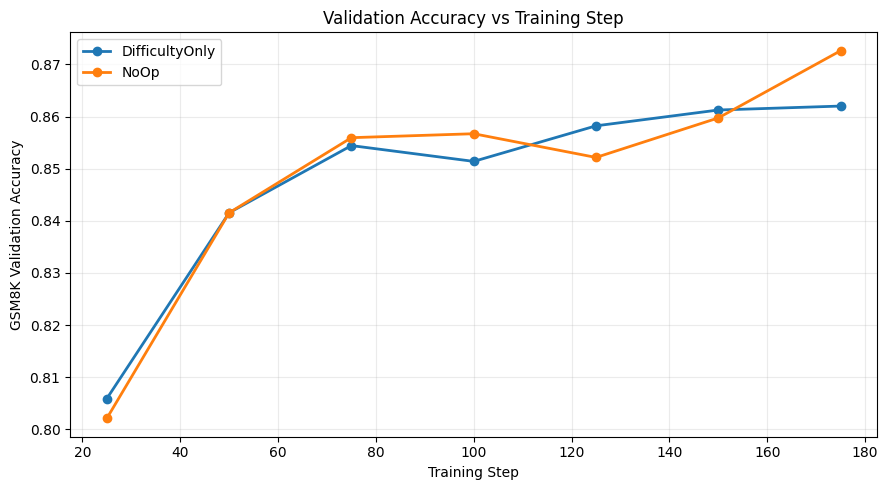


✅ Step-aligned validation comparison complete.


In [18]:
# ============================================================
# W7-M4.3 - Validation Accuracy vs Training Step
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Extract validation checkpoints
# ------------------------------------------------------------

difficulty_val = (
    difficulty_common.loc[
        difficulty_common["val_accuracy"].notna(),
        ["step", "val_accuracy"]
    ]
    .rename(
        columns={
            "val_accuracy": "difficulty_accuracy"
        }
    )
)

noop_val = (
    noop_common.loc[
        noop_common["val_accuracy"].notna(),
        ["step", "val_accuracy"]
    ]
    .rename(
        columns={
            "val_accuracy": "noop_accuracy"
        }
    )
)


# ------------------------------------------------------------
# Align by evaluation step
# ------------------------------------------------------------

accuracy_by_step = (
    difficulty_val
    .merge(
        noop_val,
        on="step",
        how="inner"
    )
    .sort_values("step")
    .reset_index(drop=True)
)

accuracy_by_step["difficulty_minus_noop"] = (
    accuracy_by_step["difficulty_accuracy"]
    - accuracy_by_step["noop_accuracy"]
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("=" * 90)
print("W7-M4.3 - VALIDATION ACCURACY VS TRAINING STEP")
print("=" * 90)

display(
    accuracy_by_step.style.format({
        "difficulty_accuracy": "{:.4f}",
        "noop_accuracy": "{:.4f}",
        "difficulty_minus_noop": "{:+.4f}",
    })
)

print("\nCheckpoint summary")
print("-" * 90)

print(
    "DifficultyOnly wins:",
    int(
        (
            accuracy_by_step["difficulty_minus_noop"] > 0
        ).sum()
    ),
    "/",
    len(accuracy_by_step)
)

print(
    "NoOp wins         :",
    int(
        (
            accuracy_by_step["difficulty_minus_noop"] < 0
        ).sum()
    ),
    "/",
    len(accuracy_by_step)
)

print(
    "Ties              :",
    int(
        (
            accuracy_by_step["difficulty_minus_noop"] == 0
        ).sum()
    ),
    "/",
    len(accuracy_by_step)
)

print(
    "\nMean checkpoint difference:",
    f"{accuracy_by_step['difficulty_minus_noop'].mean():+.4f}"
)

print(
    "Final checkpoint difference:",
    f"{accuracy_by_step['difficulty_minus_noop'].iloc[-1]:+.4f}"
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    accuracy_by_step["step"],
    accuracy_by_step["difficulty_accuracy"],
    marker="o",
    linewidth=2,
    label="DifficultyOnly",
)

plt.plot(
    accuracy_by_step["step"],
    accuracy_by_step["noop_accuracy"],
    marker="o",
    linewidth=2,
    label="NoOp",
)

plt.xlabel("Training Step")
plt.ylabel("GSM8K Validation Accuracy")
plt.title("Validation Accuracy vs Training Step")
plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert len(accuracy_by_step) == 7

assert accuracy_by_step["step"].tolist() == [
    25, 50, 75, 100, 125, 150, 175
]

print(
    "\n✅ Step-aligned validation comparison complete."
)

# W7-M4.4 - Validation Accuracy vs Cumulative Tokens

The step-based comparison shows little overall separation between the two schedulers.

However, an optimizer step is not necessarily an equal unit of compute or training exposure. The two runs consume different numbers of tokens as training progresses.

I therefore compare GSM8K validation accuracy against cumulative total tokens processed.

For each validation checkpoint, I use the cumulative sum of `perf/total_num_tokens` from the beginning of the run through that step.

This measures whether DifficultyOnly reaches a given level of validation performance using fewer training tokens than NoOp.

W7-M4.4 - ACCURACY VS CUMULATIVE TOTAL TOKENS


,step,difficulty_accuracy,difficulty_tokens,noop_accuracy,noop_tokens,token_difference,token_difference_pct
0,25,0.8059,"65,960,410",0.8021,"67,390,843","-1,430,433",-2.12%
1,50,0.8415,"118,911,016",0.8415,"120,567,953","-1,656,937",-1.37%
2,75,0.8544,"169,281,092",0.8560,"170,276,216","-995,124",-0.58%
3,100,0.8514,"218,822,901",0.8567,"217,792,840","+1,030,061",+0.47%
4,125,0.8582,"267,967,516",0.8522,"263,399,505","+4,568,011",+1.73%
5,150,0.8613,"316,727,944",0.8597,"307,103,853","+9,624,091",+3.13%
6,175,0.8620,"364,517,590",0.8726,"349,317,322","+15,200,268",+4.35%



Final shared validation checkpoint
----------------------------------------------------------------------------------------------------
Step: 175
DifficultyOnly accuracy: 0.8620
NoOp accuracy          : 0.8726
DifficultyOnly tokens  : 364,517,590
NoOp tokens            : 349,317,322
DifficultyOnly token difference: +15,200,268 (+4.35%)


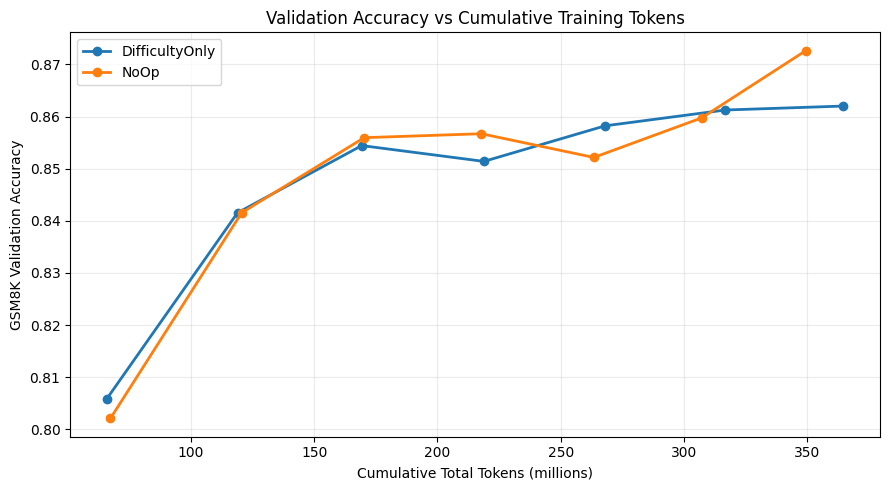


✅ Token-normalized validation comparison complete.


In [19]:
# ============================================================
# W7-M4.4 - Validation Accuracy vs Cumulative Tokens
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Extract validation checkpoints with cumulative token exposure
# ------------------------------------------------------------

difficulty_token_val = (
    difficulty_common.loc[
        difficulty_common["val_accuracy"].notna(),
        [
            "step",
            "val_accuracy",
            "cumulative_total_tokens",
        ]
    ]
    .copy()
)

difficulty_token_val["run"] = "DifficultyOnly"


noop_token_val = (
    noop_common.loc[
        noop_common["val_accuracy"].notna(),
        [
            "step",
            "val_accuracy",
            "cumulative_total_tokens",
        ]
    ]
    .copy()
)

noop_token_val["run"] = "NoOp"


token_validation = pd.concat(
    [
        difficulty_token_val,
        noop_token_val,
    ],
    ignore_index=True,
)


# Convert to millions for readability
token_validation["cumulative_total_tokens_m"] = (
    token_validation["cumulative_total_tokens"]
    / 1_000_000
)


# ------------------------------------------------------------
# Step-aligned token exposure table
# ------------------------------------------------------------

token_comparison = (
    difficulty_token_val[
        [
            "step",
            "val_accuracy",
            "cumulative_total_tokens",
        ]
    ]
    .rename(columns={
        "val_accuracy": "difficulty_accuracy",
        "cumulative_total_tokens":
            "difficulty_tokens",
    })
    .merge(
        noop_token_val[
            [
                "step",
                "val_accuracy",
                "cumulative_total_tokens",
            ]
        ]
        .rename(columns={
            "val_accuracy": "noop_accuracy",
            "cumulative_total_tokens":
                "noop_tokens",
        }),
        on="step",
        how="inner",
    )
)

token_comparison["token_difference"] = (
    token_comparison["difficulty_tokens"]
    - token_comparison["noop_tokens"]
)

token_comparison["token_difference_pct"] = (
    token_comparison["token_difference"]
    / token_comparison["noop_tokens"]
    * 100
)


print("=" * 100)
print("W7-M4.4 - ACCURACY VS CUMULATIVE TOTAL TOKENS")
print("=" * 100)

display(
    token_comparison.style.format({
        "difficulty_accuracy": "{:.4f}",
        "noop_accuracy": "{:.4f}",
        "difficulty_tokens": "{:,.0f}",
        "noop_tokens": "{:,.0f}",
        "token_difference": "{:+,.0f}",
        "token_difference_pct": "{:+.2f}%",
    })
)


# ------------------------------------------------------------
# Final validation checkpoint summary
# ------------------------------------------------------------

final_row = token_comparison.iloc[-1]

print("\nFinal shared validation checkpoint")
print("-" * 100)

print("Step:", int(final_row["step"]))

print(
    "DifficultyOnly accuracy:",
    f"{final_row['difficulty_accuracy']:.4f}"
)

print(
    "NoOp accuracy          :",
    f"{final_row['noop_accuracy']:.4f}"
)

print(
    "DifficultyOnly tokens  :",
    f"{final_row['difficulty_tokens']:,.0f}"
)

print(
    "NoOp tokens            :",
    f"{final_row['noop_tokens']:,.0f}"
)

print(
    "DifficultyOnly token difference:",
    f"{final_row['token_difference']:+,.0f}",
    f"({final_row['token_difference_pct']:+.2f}%)"
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

for run_name, group in token_validation.groupby("run"):

    group = group.sort_values(
        "cumulative_total_tokens_m"
    )

    plt.plot(
        group["cumulative_total_tokens_m"],
        group["val_accuracy"],
        marker="o",
        linewidth=2,
        label=run_name,
    )


plt.xlabel("Cumulative Total Tokens (millions)")
plt.ylabel("GSM8K Validation Accuracy")
plt.title("Validation Accuracy vs Cumulative Training Tokens")

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert len(difficulty_token_val) == 7
assert len(noop_token_val) == 7

assert (
    difficulty_token_val[
        "cumulative_total_tokens"
    ].diff().dropna() > 0
).all()

assert (
    noop_token_val[
        "cumulative_total_tokens"
    ].diff().dropna() > 0
).all()

print(
    "\n✅ Token-normalized validation comparison complete."
)

# W7-M4.5 - Time to Accuracy

The final checkpoint does not show a token-efficiency advantage for DifficultyOnly, but the learning curves cross during training.

I therefore measure how quickly each scheduler first reaches several validation-accuracy thresholds.

Because validation is only performed every 25 optimizer steps, I use the first observed evaluation checkpoint that reaches or exceeds each threshold. I do not interpolate between unobserved checkpoints.

For each threshold I report:

- first observed training step
- cumulative total tokens consumed at that point
- observed validation accuracy

If a run never reaches a threshold during the completed experiment, I report it as not reached.

In [20]:
# ============================================================
# W7-M4.5 - Time to Accuracy Thresholds
# ============================================================

import numpy as np
import pandas as pd


# ------------------------------------------------------------
# Validation tables
# ------------------------------------------------------------

difficulty_eval = (
    difficulty_common.loc[
        difficulty_common["val_accuracy"].notna(),
        [
            "step",
            "val_accuracy",
            "cumulative_total_tokens",
        ],
    ]
    .copy()
    .sort_values("step")
    .reset_index(drop=True)
)

noop_eval = (
    noop_common.loc[
        noop_common["val_accuracy"].notna(),
        [
            "step",
            "val_accuracy",
            "cumulative_total_tokens",
        ],
    ]
    .copy()
    .sort_values("step")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Thresholds
# ------------------------------------------------------------

thresholds = [
    0.82,
    0.84,
    0.85,
    0.86,
    0.87,
]


def first_observed_crossing(df, threshold):

    reached = df[
        df["val_accuracy"] >= threshold
    ]

    if reached.empty:
        return {
            "step": np.nan,
            "tokens": np.nan,
            "accuracy": np.nan,
        }

    row = reached.iloc[0]

    return {
        "step": int(row["step"]),
        "tokens": float(
            row["cumulative_total_tokens"]
        ),
        "accuracy": float(
            row["val_accuracy"]
        ),
    }


# ------------------------------------------------------------
# Build threshold table
# ------------------------------------------------------------

rows = []

for threshold in thresholds:

    diff = first_observed_crossing(
        difficulty_eval,
        threshold,
    )

    noop = first_observed_crossing(
        noop_eval,
        threshold,
    )

    rows.append({
        "threshold": threshold,

        "difficulty_step":
            diff["step"],

        "noop_step":
            noop["step"],

        "difficulty_tokens":
            diff["tokens"],

        "noop_tokens":
            noop["tokens"],

        "difficulty_accuracy":
            diff["accuracy"],

        "noop_accuracy":
            noop["accuracy"],
    })


time_to_accuracy = pd.DataFrame(rows)


# ------------------------------------------------------------
# Differences where both runs reached threshold
# ------------------------------------------------------------

time_to_accuracy["step_difference"] = (
    time_to_accuracy["difficulty_step"]
    - time_to_accuracy["noop_step"]
)

time_to_accuracy["token_difference"] = (
    time_to_accuracy["difficulty_tokens"]
    - time_to_accuracy["noop_tokens"]
)

time_to_accuracy["token_difference_pct"] = (
    time_to_accuracy["token_difference"]
    / time_to_accuracy["noop_tokens"]
    * 100
)


# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("=" * 110)
print("W7-M4.5 - FIRST OBSERVED TIME TO ACCURACY")
print("=" * 110)

display(
    time_to_accuracy.style.format(
        {
            "threshold": "{:.2f}",
            "difficulty_step": "{:.0f}",
            "noop_step": "{:.0f}",
            "difficulty_tokens": "{:,.0f}",
            "noop_tokens": "{:,.0f}",
            "difficulty_accuracy": "{:.4f}",
            "noop_accuracy": "{:.4f}",
            "step_difference": "{:+.0f}",
            "token_difference": "{:+,.0f}",
            "token_difference_pct": "{:+.2f}%",
        },
        na_rep="Not reached",
    )
)


# ------------------------------------------------------------
# Human-readable summary
# ------------------------------------------------------------

print("\nThreshold summary")
print("-" * 110)

for _, row in time_to_accuracy.iterrows():

    threshold = row["threshold"]

    d_step = row["difficulty_step"]
    n_step = row["noop_step"]

    if pd.isna(d_step) and pd.isna(n_step):

        print(
            f"{threshold:.2f}: neither run reached threshold"
        )

    elif pd.isna(d_step):

        print(
            f"{threshold:.2f}: NoOp reached it at "
            f"step {int(n_step)}, DifficultyOnly did not"
        )

    elif pd.isna(n_step):

        print(
            f"{threshold:.2f}: DifficultyOnly reached it at "
            f"step {int(d_step)}, NoOp did not"
        )

    else:

        if d_step < n_step:
            winner = "DifficultyOnly"
        elif n_step < d_step:
            winner = "NoOp"
        else:
            winner = "Tie"

        print(
            f"{threshold:.2f}: {winner} | "
            f"DifficultyOnly step {int(d_step)}, "
            f"NoOp step {int(n_step)}"
        )


print(
    "\n✅ First-observed time-to-accuracy analysis complete."
)

W7-M4.5 - FIRST OBSERVED TIME TO ACCURACY


,threshold,difficulty_step,noop_step,difficulty_tokens,noop_tokens,difficulty_accuracy,noop_accuracy,step_difference,token_difference,token_difference_pct
0,0.82,50,50,"118,911,016","120,567,953",0.8415,0.8415,+0,"-1,656,937",-1.37%
1,0.84,50,50,"118,911,016","120,567,953",0.8415,0.8415,+0,"-1,656,937",-1.37%
2,0.85,75,75,"169,281,092","170,276,216",0.8544,0.8560,+0,"-995,124",-0.58%
3,0.86,150,175,"316,727,944","349,317,322",0.8613,0.8726,-25,"-32,589,378",-9.33%
4,0.87,Not reached,175,Not reached,"349,317,322",Not reached,0.8726,Not reached,Not reached,Not reached



Threshold summary
--------------------------------------------------------------------------------------------------------------
0.82: Tie | DifficultyOnly step 50, NoOp step 50
0.84: Tie | DifficultyOnly step 50, NoOp step 50
0.85: Tie | DifficultyOnly step 75, NoOp step 75
0.86: DifficultyOnly | DifficultyOnly step 150, NoOp step 175
0.87: NoOp reached it at step 175, DifficultyOnly did not

✅ First-observed time-to-accuracy analysis complete.


# W7-M4.7 - DifficultyOnly Skip-Rate Trend

I now test whether DifficultyOnly becomes less aggressive as training progresses.

The scheduler uses the refill policy, so every completed optimizer step still contains 512 selected prompts. A skipped prompt is therefore a rejected candidate that is replaced before the final training batch is formed.

I define the candidate skip rate as:

`skipped candidates / (skipped candidates + selected prompts)`

This measures how aggressively the scheduler filters the candidate stream rather than how much it shrinks the final training batch.

I examine the raw per-step skip rate, a rolling average for visualization, and the relationship between training step and skip rate.

W7-M4.7 - DIFFICULTYONLY CANDIDATE SKIP-RATE TREND

Overall mean candidate skip rate: 0.3828 (38.28%)
Overall median candidate skip rate: 0.4234 (42.34%)
Total skipped candidates: 75,843

Phase summary
----------------------------------------------------------------------------------------------------


,phase,steps,mean_skip_rate,median_skip_rate,mean_easy_rate,mean_hard_rate,total_skipped
0,Early,59,11.96%,13.07%,9.66%,2.30%,"4,502"
1,Middle,59,41.53%,42.21%,39.64%,1.89%,"22,337"
2,Late,60,60.97%,61.39%,59.04%,1.94%,"49,004"



Trend statistics
----------------------------------------------------------------------------------------------------
Spearman(step, skip rate): rho = +0.9958 p = 7.573e-185
Linear slope per step: +0.004117
Approx. percentage-point change over 100 steps: +41.17 pp


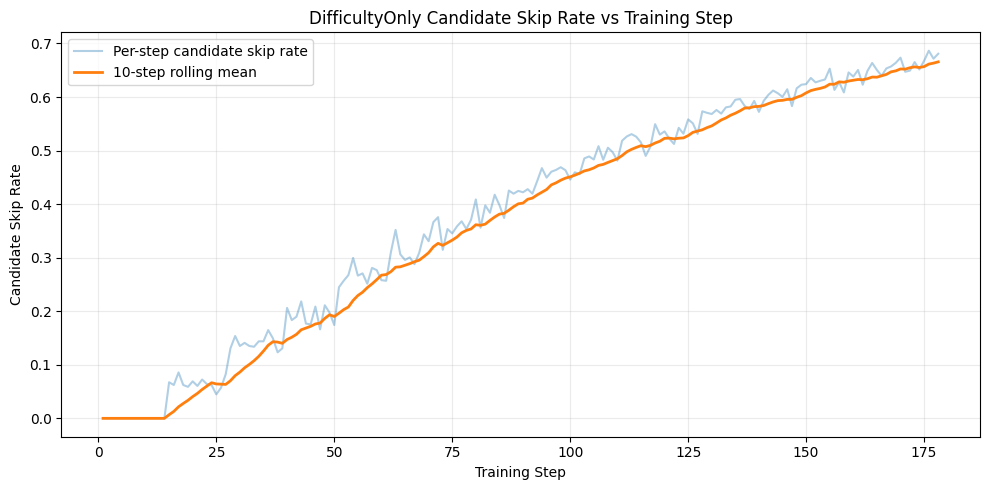


✅ DifficultyOnly skip-rate trend analysis complete.


In [21]:
# ============================================================
# W7-M4.7 - DifficultyOnly Candidate Skip-Rate Trend
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import spearmanr, linregress


# ------------------------------------------------------------
# Build DifficultyOnly skip table
# ------------------------------------------------------------

skip_df = difficulty_common[
    [
        "step",
        "prompts_selected",
        "skipped_easy",
        "skipped_hard",
        "skipped_total",
    ]
].copy()


# Total candidate prompts encountered before refill finishes
skip_df["candidate_prompts"] = (
    skip_df["prompts_selected"]
    + skip_df["skipped_total"]
)


# Candidate-level rejection rate
skip_df["candidate_skip_rate"] = (
    skip_df["skipped_total"]
    / skip_df["candidate_prompts"]
)


# Separate easy/hard contribution rates
skip_df["easy_skip_rate"] = (
    skip_df["skipped_easy"]
    / skip_df["candidate_prompts"]
)

skip_df["hard_skip_rate"] = (
    skip_df["skipped_hard"]
    / skip_df["candidate_prompts"]
)


# Rolling average only for visualization
skip_df["skip_rate_roll10"] = (
    skip_df["candidate_skip_rate"]
    .rolling(
        window=10,
        min_periods=1
    )
    .mean()
)


# ------------------------------------------------------------
# Early / middle / late thirds
# ------------------------------------------------------------

skip_df["phase"] = pd.cut(
    skip_df["step"],
    bins=[
        0,
        COMMON_LAST_STEP / 3,
        2 * COMMON_LAST_STEP / 3,
        COMMON_LAST_STEP,
    ],
    labels=[
        "Early",
        "Middle",
        "Late",
    ],
    include_lowest=True,
)


phase_summary = (
    skip_df
    .groupby(
        "phase",
        observed=True
    )
    .agg(
        steps=("step", "count"),
        mean_skip_rate=(
            "candidate_skip_rate",
            "mean"
        ),
        median_skip_rate=(
            "candidate_skip_rate",
            "median"
        ),
        mean_easy_rate=(
            "easy_skip_rate",
            "mean"
        ),
        mean_hard_rate=(
            "hard_skip_rate",
            "mean"
        ),
        total_skipped=(
            "skipped_total",
            "sum"
        ),
    )
    .reset_index()
)


# ------------------------------------------------------------
# Trend statistics
# ------------------------------------------------------------

rho, spearman_p = spearmanr(
    skip_df["step"],
    skip_df["candidate_skip_rate"]
)

linear = linregress(
    skip_df["step"],
    skip_df["candidate_skip_rate"]
)


# ------------------------------------------------------------
# Output
# ------------------------------------------------------------

print("=" * 100)
print("W7-M4.7 - DIFFICULTYONLY CANDIDATE SKIP-RATE TREND")
print("=" * 100)

print(
    "\nOverall mean candidate skip rate:",
    f"{skip_df['candidate_skip_rate'].mean():.4f}",
    f"({skip_df['candidate_skip_rate'].mean() * 100:.2f}%)"
)

print(
    "Overall median candidate skip rate:",
    f"{skip_df['candidate_skip_rate'].median():.4f}",
    f"({skip_df['candidate_skip_rate'].median() * 100:.2f}%)"
)

print(
    "Total skipped candidates:",
    f"{skip_df['skipped_total'].sum():,.0f}"
)

print("\nPhase summary")
print("-" * 100)

display(
    phase_summary.style.format({
        "mean_skip_rate": "{:.2%}",
        "median_skip_rate": "{:.2%}",
        "mean_easy_rate": "{:.2%}",
        "mean_hard_rate": "{:.2%}",
        "total_skipped": "{:,.0f}",
    })
)


print("\nTrend statistics")
print("-" * 100)

print(
    "Spearman(step, skip rate):",
    f"rho = {rho:+.4f}",
    f"p = {spearman_p:.4g}"
)

print(
    "Linear slope per step:",
    f"{linear.slope:+.6f}"
)

print(
    "Approx. percentage-point change over 100 steps:",
    f"{linear.slope * 100 * 100:+.2f} pp"
)


# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    skip_df["step"],
    skip_df["candidate_skip_rate"],
    alpha=0.35,
    label="Per-step candidate skip rate",
)

plt.plot(
    skip_df["step"],
    skip_df["skip_rate_roll10"],
    linewidth=2,
    label="10-step rolling mean",
)

plt.xlabel("Training Step")
plt.ylabel("Candidate Skip Rate")
plt.title(
    "DifficultyOnly Candidate Skip Rate vs Training Step"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert (
    skip_df["candidate_skip_rate"]
    .between(0, 1)
    .all()
)

assert (
    skip_df["prompts_selected"] == 512
).all()

assert (
    skip_df["skipped_total"] >= 0
).all()

print(
    "\n✅ DifficultyOnly skip-rate trend analysis complete."
)

In [22]:
print("Overall mean candidate skip rate:",
      f"{skip_df['candidate_skip_rate'].mean():.4f}",
      f"({skip_df['candidate_skip_rate'].mean()*100:.2f}%)")

print("Overall median candidate skip rate:",
      f"{skip_df['candidate_skip_rate'].median():.4f}",
      f"({skip_df['candidate_skip_rate'].median()*100:.2f}%)")

print("\nPhase summary:")
display(
    phase_summary[
        [
            "phase",
            "mean_skip_rate",
            "median_skip_rate",
            "mean_easy_rate",
            "mean_hard_rate",
            "total_skipped"
        ]
    ]
)

print("\nSpearman:")
print("rho =", rho)
print("p   =", spearman_p)

print("\nLinear slope per step:")
print(linear.slope)

print("\nPercentage-point change over 100 steps:")
print(linear.slope * 100 * 100)

Overall mean candidate skip rate: 0.3828 (38.28%)
Overall median candidate skip rate: 0.4234 (42.34%)

Phase summary:


,phase,mean_skip_rate,median_skip_rate,mean_easy_rate,mean_hard_rate,total_skipped
0,Early,0.119615,0.130730,0.096600,0.023015,4502.0
1,Middle,0.415335,0.422122,0.396391,0.018944,22337.0
2,Late,0.609739,0.613875,0.590356,0.019383,49004.0



Spearman:
rho = 0.9958172886371669
p   = 7.573387366832247e-185

Linear slope per step:
0.004116791710463446

Percentage-point change over 100 steps:
41.167917104634455


# W7-M4.8 - Freeze the Long-Run Result

I now freeze the empirical result of the long-run NoOp versus DifficultyOnly comparison.

The two runs are independent sequential training runs rather than an interleaved paired experiment, so I do not report a paired significance test across validation checkpoints.

The main empirical findings are:

- step-normalized validation performance is very similar through most of training
- DifficultyOnly reaches 0.86 validation accuracy 25 steps earlier
- reaching 0.86 requires about 32.6 million fewer total tokens, a 9.33% reduction relative to NoOp
- DifficultyOnly does not reach 0.87 during the completed run
- NoOp reaches 0.8726 at step 175
- DifficultyOnly candidate filtering becomes substantially more aggressive over training rather than declining
- the growth in filtering is driven almost entirely by the easy-streak path

I save these results as the frozen Week 7 long-run summary.

In [23]:
# ============================================================
# W7-M4.8 - Freeze Final Long-Run Result
# ============================================================

import pandas as pd


# ------------------------------------------------------------
# Key threshold rows
# ------------------------------------------------------------

threshold_086 = (
    time_to_accuracy.loc[
        time_to_accuracy["threshold"] == 0.86
    ]
    .iloc[0]
)

threshold_087 = (
    time_to_accuracy.loc[
        time_to_accuracy["threshold"] == 0.87
    ]
    .iloc[0]
)


# ------------------------------------------------------------
# Final validation checkpoint
# ------------------------------------------------------------

final_eval = accuracy_by_step.iloc[-1]


# ------------------------------------------------------------
# Skip phases
# ------------------------------------------------------------

early_skip = phase_summary.loc[
    phase_summary["phase"] == "Early"
].iloc[0]

middle_skip = phase_summary.loc[
    phase_summary["phase"] == "Middle"
].iloc[0]

late_skip = phase_summary.loc[
    phase_summary["phase"] == "Late"
].iloc[0]


# ------------------------------------------------------------
# Freeze result table
# ------------------------------------------------------------

long_run_final = pd.DataFrame([
    {
        "metric": "completed_steps",
        "DifficultyOnly": len(difficulty_df),
        "NoOp": len(noop_df),
        "difference": len(difficulty_df) - len(noop_df),
    },
    {
        "metric": "accuracy_at_step_175",
        "DifficultyOnly": final_eval["difficulty_accuracy"],
        "NoOp": final_eval["noop_accuracy"],
        "difference": final_eval["difficulty_minus_noop"],
    },
    {
        "metric": "first_step_accuracy_0.86",
        "DifficultyOnly": threshold_086["difficulty_step"],
        "NoOp": threshold_086["noop_step"],
        "difference": threshold_086["step_difference"],
    },
    {
        "metric": "tokens_to_accuracy_0.86",
        "DifficultyOnly": threshold_086["difficulty_tokens"],
        "NoOp": threshold_086["noop_tokens"],
        "difference": threshold_086["token_difference"],
    },
    {
        "metric": "accuracy_0.86_token_difference_pct",
        "DifficultyOnly": threshold_086["token_difference_pct"],
        "NoOp": 0.0,
        "difference": threshold_086["token_difference_pct"],
    },
    {
        "metric": "reached_accuracy_0.87",
        "DifficultyOnly": 0,
        "NoOp": 1,
        "difference": -1,
    },
    {
        "metric": "mean_candidate_skip_rate",
        "DifficultyOnly": skip_df["candidate_skip_rate"].mean(),
        "NoOp": 0.0,
        "difference": skip_df["candidate_skip_rate"].mean(),
    },
    {
        "metric": "early_candidate_skip_rate",
        "DifficultyOnly": early_skip["mean_skip_rate"],
        "NoOp": 0.0,
        "difference": early_skip["mean_skip_rate"],
    },
    {
        "metric": "middle_candidate_skip_rate",
        "DifficultyOnly": middle_skip["mean_skip_rate"],
        "NoOp": 0.0,
        "difference": middle_skip["mean_skip_rate"],
    },
    {
        "metric": "late_candidate_skip_rate",
        "DifficultyOnly": late_skip["mean_skip_rate"],
        "NoOp": 0.0,
        "difference": late_skip["mean_skip_rate"],
    },
    {
        "metric": "skip_rate_spearman_rho",
        "DifficultyOnly": rho,
        "NoOp": 0.0,
        "difference": rho,
    },
])


# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

long_run_final.to_csv(
    "week7_long_run_final_summary.csv",
    index=False,
)

accuracy_by_step.to_csv(
    "week7_long_run_accuracy_by_step.csv",
    index=False,
)

time_to_accuracy.to_csv(
    "week7_long_run_time_to_accuracy.csv",
    index=False,
)

phase_summary.to_csv(
    "week7_long_run_skip_phase_summary.csv",
    index=False,
)


print("=" * 100)
print("W7-M4.8 - FINAL LONG-RUN RESULT")
print("=" * 100)

display(long_run_final)

print("\nCore conclusion:")
print(
    "DifficultyOnly reaches 0.86 accuracy 25 steps earlier "
    "and with 9.33% fewer total tokens, but NoOp achieves "
    "the higher late-run validation accuracy (0.8726 vs 0.8620 "
    "at step 175). DifficultyOnly filtering becomes more "
    "aggressive over training, rising from 11.96% candidate "
    "rejection early to 60.97% late."
)

print(
    "\n✅ Week 7 long-run empirical analysis frozen."
)

W7-M4.8 - FINAL LONG-RUN RESULT


,metric,DifficultyOnly,NoOp,difference
0,completed_steps,1.800000e+02,1.780000e+02,2.000000e+00
1,accuracy_at_step_175,8.620167e-01,8.726308e-01,-1.061410e-02
2,first_step_accuracy_0.86,1.500000e+02,1.750000e+02,-2.500000e+01
3,tokens_to_accuracy_0.86,3.167279e+08,3.493173e+08,-3.258938e+07
4,accuracy_0.86_token_difference_pct,-9.329448e+00,0.000000e+00,-9.329448e+00
5,reached_accuracy_0.87,0.000000e+00,1.000000e+00,-1.000000e+00
6,mean_candidate_skip_rate,3.828449e-01,0.000000e+00,3.828449e-01
7,early_candidate_skip_rate,1.196151e-01,0.000000e+00,1.196151e-01
8,middle_candidate_skip_rate,4.153349e-01,0.000000e+00,4.153349e-01
9,late_candidate_skip_rate,6.097391e-01,0.000000e+00,6.097391e-01



Core conclusion:
DifficultyOnly reaches 0.86 accuracy 25 steps earlier and with 9.33% fewer total tokens, but NoOp achieves the higher late-run validation accuracy (0.8726 vs 0.8620 at step 175). DifficultyOnly filtering becomes more aggressive over training, rising from 11.96% candidate rejection early to 60.97% late.

✅ Week 7 long-run empirical analysis frozen.


# W7-M1.9 — Predictor vs Streak Across Skip Budgets

The previous comparison used Sam's observed average expected skip budget of 23.3%.

That single operating point hides how the two ranking rules behave as filtering becomes more or less aggressive.

I therefore sweep a common skip budget from 0% to 70%.

At every budget, both rules are allowed to skip exactly the same expected number of prompt-step cases. I rank prompts using:

- DifficultyOnly: exact streak-rule expected skip probability
- History model: frozen Week 5 dead probability

Tied scores are handled fractionally rather than broken arbitrarily.

For each budget I measure:

- dead prompts caught
- informative prompts lost
- fraction of all dead prompts caught
- fraction of all informative prompts lost

Because the total skip budget is matched, every additional dead prompt caught is exactly one informative prompt spared.

The 0–70% sweep is an operating-point sensitivity analysis on the available Week 7 live-run data. Budgets near 60–70% correspond to the filtering intensity observed later in the separate long run, but they should not be interpreted as a direct evaluation on that later training distribution.

W7-M1.9 — PREDICTOR VS STREAK ACROSS SKIP BUDGETS


,budget,streak_dead_caught,history_dead_caught,streak_informative_lost,history_informative_lost,history_minus_streak_dead
0,5%,75.22,50.84,20.78,45.16,-24.38
1,10%,138.21,101.68,53.79,90.32,-36.53
2,20%,231.93,203.05,152.07,180.95,-28.87
3,30%,303.55,291.91,272.45,284.09,-11.64
4,40%,363.49,373.26,404.51,394.74,+9.78
5,50%,411.01,438.19,548.99,521.81,+27.18
6,60%,456.41,493.82,695.59,658.18,+37.41
7,67%,488.19,527.72,798.21,758.68,+39.53
8,70%,501.81,541.31,842.19,802.69,+39.51



Winner by budget:
--------------------------------------------------------------------------------------------------------------
5%: Streak  | History - Streak dead caught = -24.38
10%: Streak  | History - Streak dead caught = -36.53
20%: Streak  | History - Streak dead caught = -28.87
30%: Streak  | History - Streak dead caught = -11.64
40%: History | History - Streak dead caught = +9.78
50%: History | History - Streak dead caught = +27.18
60%: History | History - Streak dead caught = +37.41
67%: History | History - Streak dead caught = +39.53
70%: History | History - Streak dead caught = +39.51


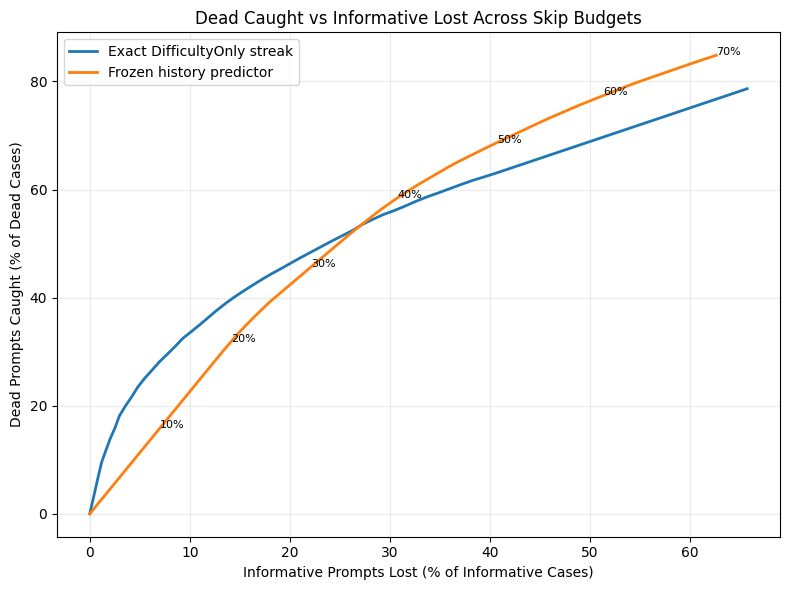

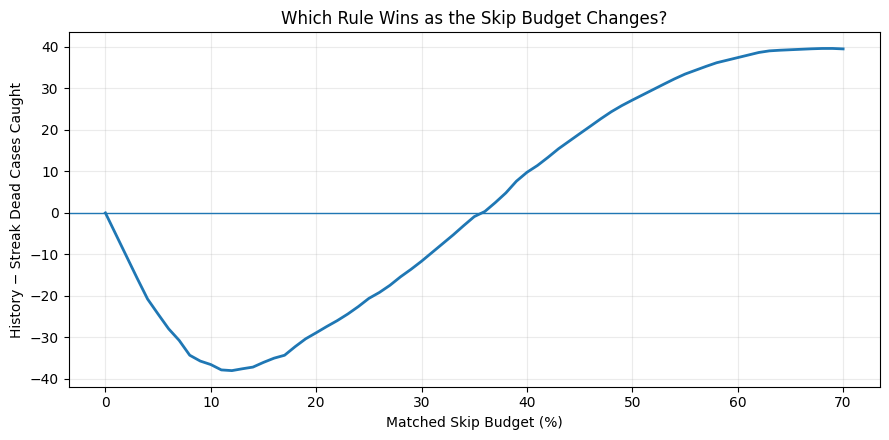


✅ Budget sweep complete from 0% to 70%.


In [24]:
# ============================================================
# W7-M1.9 — Dead Caught vs Informative Lost Across Budgets
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Use the already-validated leakage-free evaluation table
# ------------------------------------------------------------

required_cols = {
    "step",
    "current_dead",
    "sam_expected_skip_prob",
    "history_dead_prob",
}

missing = required_cols - set(exact_eval.columns)

assert not missing, (
    f"exact_eval is missing required columns: {missing}"
)

budget_base = (
    exact_eval[
        [
            "step",
            "current_dead",
            "sam_expected_skip_prob",
            "history_dead_prob",
        ]
    ]
    .copy()
    .reset_index(drop=True)
)

budget_base["current_dead"] = (
    budget_base["current_dead"].astype(float)
)


# ------------------------------------------------------------
# Fractional top-budget selector
#
# If a score tie crosses the budget boundary, every member of
# that tie receives the same fractional skip probability.
# ------------------------------------------------------------

def fractional_top_budget(scores, budget_fraction):

    scores = np.asarray(scores, dtype=float)

    n = len(scores)
    target = float(budget_fraction) * n

    q = np.zeros(n, dtype=float)

    if target <= 0:
        return q

    if target >= n:
        return np.ones(n, dtype=float)

    unique_scores = np.sort(
        np.unique(scores)
    )[::-1]

    remaining = target

    for score in unique_scores:

        idx = np.flatnonzero(
            scores == score
        )

        group_n = len(idx)

        if remaining >= group_n:

            q[idx] = 1.0
            remaining -= group_n

        else:

            if remaining > 0:
                q[idx] = remaining / group_n

            break

    return q


# ------------------------------------------------------------
# Evaluate one ranking rule at one fixed budget.
#
# The budget is enforced separately inside every step so that
# no training step can dominate simply because its score scale
# is different.
# ------------------------------------------------------------

def evaluate_budget(df, score_col, budget_fraction):

    parts = []

    for step, g in df.groupby(
        "step",
        sort=True
    ):

        g = g.copy()

        g["q"] = fractional_top_budget(
            g[score_col].to_numpy(),
            budget_fraction,
        )

        parts.append(g)

    scored = pd.concat(
        parts,
        ignore_index=True
    )

    y = scored["current_dead"].to_numpy()
    q = scored["q"].to_numpy()

    tp = np.sum(q * y)
    fp = np.sum(q * (1 - y))

    fn = np.sum((1 - q) * y)
    tn = np.sum((1 - q) * (1 - y))

    total_dead = tp + fn
    total_informative = fp + tn

    return {
        "dead_caught": tp,
        "informative_lost": fp,

        "dead_caught_rate":
            tp / total_dead,

        "informative_lost_rate":
            fp / total_informative,

        "expected_skips":
            tp + fp,
    }


# ------------------------------------------------------------
# Sweep 0% through 70% in one-percentage-point increments
# ------------------------------------------------------------

budgets = np.arange(
    0.00,
    0.701,
    0.01
)

rows = []

for budget in budgets:

    streak = evaluate_budget(
        budget_base,
        "sam_expected_skip_prob",
        budget,
    )

    history = evaluate_budget(
        budget_base,
        "history_dead_prob",
        budget,
    )

    rows.append({
        "budget": budget,

        "streak_dead_caught":
            streak["dead_caught"],

        "history_dead_caught":
            history["dead_caught"],

        "streak_informative_lost":
            streak["informative_lost"],

        "history_informative_lost":
            history["informative_lost"],

        "streak_dead_caught_rate":
            streak["dead_caught_rate"],

        "history_dead_caught_rate":
            history["dead_caught_rate"],

        "streak_informative_lost_rate":
            streak["informative_lost_rate"],

        "history_informative_lost_rate":
            history["informative_lost_rate"],

        "history_minus_streak_dead":
            history["dead_caught"]
            - streak["dead_caught"],

        "history_minus_streak_informative_lost":
            history["informative_lost"]
            - streak["informative_lost"],
    })


budget_curve = pd.DataFrame(rows)


# ------------------------------------------------------------
# Sanity check:
# matched budgets mean delta dead caught must be exactly
# the negative of delta informative lost.
# ------------------------------------------------------------

assert np.allclose(
    budget_curve[
        "history_minus_streak_dead"
    ],
    -budget_curve[
        "history_minus_streak_informative_lost"
    ],
    atol=1e-8,
)


# ------------------------------------------------------------
# Compact operating-point table
# ------------------------------------------------------------

report_budgets = [
    0.05,
    0.10,
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.67,
    0.70,
]

report_rows = []

for b in report_budgets:

    idx = (
        budget_curve["budget"] - b
    ).abs().idxmin()

    report_rows.append(
        budget_curve.loc[idx]
    )

budget_report = pd.DataFrame(
    report_rows
).reset_index(drop=True)


print("=" * 110)
print("W7-M1.9 — PREDICTOR VS STREAK ACROSS SKIP BUDGETS")
print("=" * 110)

display(
    budget_report[
        [
            "budget",
            "streak_dead_caught",
            "history_dead_caught",
            "streak_informative_lost",
            "history_informative_lost",
            "history_minus_streak_dead",
        ]
    ].style.format({
        "budget": "{:.0%}",
        "streak_dead_caught": "{:.2f}",
        "history_dead_caught": "{:.2f}",
        "streak_informative_lost": "{:.2f}",
        "history_informative_lost": "{:.2f}",
        "history_minus_streak_dead": "{:+.2f}",
    })
)


# ------------------------------------------------------------
# Find budget regions where each rule wins
# ------------------------------------------------------------

budget_curve["winner"] = np.select(
    [
        budget_curve[
            "history_minus_streak_dead"
        ] > 1e-9,

        budget_curve[
            "history_minus_streak_dead"
        ] < -1e-9,
    ],
    [
        "History",
        "Streak",
    ],
    default="Tie",
)

print("\nWinner by budget:")
print("-" * 110)

for _, row in budget_report.iterrows():

    idx = (
        budget_curve["budget"]
        - row["budget"]
    ).abs().idxmin()

    winner = budget_curve.loc[
        idx,
        "winner"
    ]

    delta = budget_curve.loc[
        idx,
        "history_minus_streak_dead"
    ]

    print(
        f"{row['budget']:.0%}: "
        f"{winner:7s} | "
        f"History - Streak dead caught = "
        f"{delta:+.2f}"
    )


# ------------------------------------------------------------
# Main requested curve:
# dead caught vs informative lost
# ------------------------------------------------------------

plt.figure(figsize=(8, 6))

plt.plot(
    budget_curve[
        "streak_informative_lost_rate"
    ] * 100,
    budget_curve[
        "streak_dead_caught_rate"
    ] * 100,
    linewidth=2,
    label="Exact DifficultyOnly streak",
)

plt.plot(
    budget_curve[
        "history_informative_lost_rate"
    ] * 100,
    budget_curve[
        "history_dead_caught_rate"
    ] * 100,
    linewidth=2,
    label="Frozen history predictor",
)


# Annotate every 10% budget
for b in np.arange(
    0.10,
    0.71,
    0.10
):

    idx = (
        budget_curve["budget"] - b
    ).abs().idxmin()

    row = budget_curve.loc[idx]

    plt.annotate(
        f"{int(round(b * 100))}%",
        (
            row[
                "history_informative_lost_rate"
            ] * 100,
            row[
                "history_dead_caught_rate"
            ] * 100,
        ),
        fontsize=8,
    )


plt.xlabel(
    "Informative Prompts Lost (% of Informative Cases)"
)

plt.ylabel(
    "Dead Prompts Caught (% of Dead Cases)"
)

plt.title(
    "Dead Caught vs Informative Lost Across Skip Budgets"
)

plt.legend()
plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# Difference curve makes crossover budgets obvious
# ------------------------------------------------------------

plt.figure(figsize=(9, 4.5))

plt.plot(
    budget_curve["budget"] * 100,
    budget_curve[
        "history_minus_streak_dead"
    ],
    linewidth=2,
)

plt.axhline(
    0,
    linewidth=1,
)

plt.xlabel("Matched Skip Budget (%)")

plt.ylabel(
    "History − Streak Dead Cases Caught"
)

plt.title(
    "Which Rule Wins as the Skip Budget Changes?"
)

plt.grid(alpha=0.25)

plt.tight_layout()
plt.show()


print(
    "\n✅ Budget sweep complete from 0% to 70%."
)